# How the F-19 planner works

This notebook walks through `f19.planner` in the order it does its work, one step at a time, on **real plans**
(the fixtures in `$F19_DATA/fixtures/plans/`: the mission read from the game's briefing screen, the `plan.json` that was
planned, and the `route.json` / `report.txt` that came out). Every code cell calls the planner's own functions, so you can
change a number and re-run it.

```
 plan.json + mission_mem.json
        |
 1  profile        hard limits + objective weights                 profiles.py
 2  World          terrain walls, territory, SA-14 cells, bases     world.py
 3  RadarModel     the game's radar rules -> "is the plane seen?"   radar.py (rules/radar.py)
 4  Regimes        throttle / flaps / speed / fuel burn             fuelplan.py (rules/fuel.py)
 5  Router costs   every grid move priced in "transit km"           router.py  Router.__init__
 6  skeleton       takeoff piece, targets, landing piece, attack geometry   planner.py
 7  routing        search -> reduce -> expand -> repair -> densify -> validate     router.py
 8  fuel + altitude   integrate() walks the route in game time     fuelplan.py
 9  alert sim      per-site alert, pulse by pulse                   alertsim.py
10  options        order x approach side x attack bearings x loiters, pick the cheapest   planner.py run()
11  outputs        summary, report.txt, route.png, route.json       report.py
12  in flight      route(pose, goals): the fast, bounded planner     api.py
13  career points  optimise points and survival instead of fuel: damage model from the game code and the logs   (at the end)
```

**Units.** Everything inside the planner is in *game units*, **64 per km** (`K`). Plots below are in km, with north up
(the game's y axis points south, so `y` grows downward, heading 0 = north = -y).

**Run time.** The first cell of each step is fast (seconds). Cells marked **(slow)** take 30 s - 3 min and sit behind a flag.

In [1]:
import json, math, re, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle

from f19.core.settings import settings as S
from f19.planner import profiles, fuelplan, alertsim, report, loiter, api
from f19.planner.planner import Planner
from f19.planner.router import hdg, unit, from_hdg, nearest_dir, MOVES, DIR_ANG
from f19.planner.world import K, CELL_KM, GROUND_KMH_PER_KT
from f19.planner.estimate import FuelConstraint

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 9})

FIXTURES = S.data / "fixtures/plans"
print("data:", S.data)
print("plans:", sorted(p.name for p in FIXTURES.iterdir()))

data: /Users/robmaxwell/f19-data
plans: ['ce_budejovice_1023_1811', 'ce_kolobrzeg_1022_2250', 'ce_liberec_1027_0916', 'pg_shiraz_1024_1514']


## Setup: load a plan and some plotting helpers

`PLAN` picks the example used through the notebook. Everything below works for any of the four fixtures
(the PG one is Persian Gulf; the Liberec one has a Maverick attack instead of a photo run).

In [2]:
PLAN = "ce_kolobrzeg_1022_2250"     # try: pg_shiraz_1024_1514, ce_liberec_1027_0916, ce_budejovice_1023_1811
RUN_SLOW = False                    # True: also run the 30 s - 3 min cells

def load_plan(name):
    D = FIXTURES / name
    spec = json.load(open(D / "plan.json"))
    mission = json.load(open(D / "mission_mem.json"))
    route = json.load(open(D / "route.json"))              # what the planner produced (stored)
    spec = {**spec, "takeoff_heading": api.resolve_takeoff_heading(spec, mission)}
    return D, spec, mission, route

_planners = {}
def get_planner(name, loiters=False, **spec_over):
    """Planner for a fixture (cached). spec_over: keys merged into plan.json, e.g. profile="fast"."""
    key = (name, loiters, json.dumps(spec_over, sort_keys=True, default=str))
    if key not in _planners:
        D, spec, M, _ = load_plan(name)
        _planners[key] = Planner({**spec, **spec_over}, M, str(D), loiters=loiters)
    return _planners[key]

def chosen_sequence(pl, chosen):
    """Rebuild the planner's sequence for a stored 'chosen' tag, e.g.
    'order primary/secondary, approach S, primary photo on 90, secondary photo on 270'."""
    order = re.search(r"order ([\w/]+)", chosen).group(1).split("/")
    side = re.search(r"approach ([NS])", chosen).group(1)
    seq = [pl.takeoff(), *pl.targets(order), pl.landing(side)]
    tg = {t["role"].rstrip("?"): t for t in pl.M["targets"]}
    for k, el in enumerate(seq):
        if el["t"] == "target":
            m = re.search(rf"{el['role']} (photo|maverick) on (\d+)", chosen)
            if m: seq[k] = pl.attack_piece(el, tg[el["role"]], m.group(1), float(m.group(2)))
    return seq

D, spec, M, stored = load_plan(PLAN)
pl = get_planner(PLAN)
print(PLAN, "->", stored["chosen"])
print("targets:", [(t["role"], t["task"], t["object"], t["place"]) for t in M["targets"]])

ce_kolobrzeg_1022_2250 -> order primary/secondary, approach S, primary photo on 90, secondary photo on 270
targets: [('primary', 'photograph', 'SAM Radar', 'Kolobrzeg'), ('secondary', 'photograph', 'Tank Farm', 'Liberec')]


In [3]:
# --- plotting helpers (km, north up) ---------------------------------------------------------------------------
def km(a): return np.asarray(a, float) / K

def xy_of(pts):
    """Accepts planner points [(xy, label, attrs)], route.json point dicts, or a bare xy list."""
    out = []
    for p in pts:
        if isinstance(p, dict): out.append((p["x"], p["y"]))
        elif len(p) == 3 and not np.isscalar(p[0]): out.append(tuple(p[0]))
        else: out.append(tuple(p))
    return km(out)

def draw_world(ax, pl, crop=None, terrain=True, territory=True, sa14=True, radars=True, bases=True, targets=True, labels=True):
    W = pl.W; L = W.size / K
    if terrain: ax.imshow(np.minimum(W.H, 3000), cmap="Greys", vmax=4500, extent=(0, L, L, 0), alpha=.75, interpolation="nearest")
    if territory:
        ax.imshow(np.where(W.enemy_grid, 1.0, np.nan), cmap=ListedColormap(["#d62728"]), alpha=.10, extent=(0, L, L, 0))
    if sa14 and W.sa14_cells.any():
        for cy, cx in zip(*np.nonzero(W.sa14_cells)):
            ax.add_patch(plt.Rectangle((cx * 32, cy * 32), 32, 32, fc="#ff7f0e", alpha=.25, ec="#ff7f0e", lw=.5))
    if bases:
        for n, (x, y) in W.airbases.items():
            ax.plot(x / K, y / K, "s", c="#1f77b4", ms=4)
            if labels: ax.annotate(n, (x / K, y / K), xytext=(3, 3), textcoords="offset points", fontsize=6.5, color="#1f77b4")
    if radars:
        for r in W.radars:
            ax.plot(r["x"] / K, r["y"] / K, "^" if r["type"] == "P" else "v", c="#d62728", ms=5)
            if labels: ax.annotate(f"{r['place']} {r['system']}", (r["x"] / K, r["y"] / K), xytext=(3, -8), textcoords="offset points", fontsize=6, color="#d62728")
    if targets:
        for t in pl.M["targets"]:
            ax.plot(t["x"] / K, t["y"] / K, "*", c="gold", mec="k", ms=11, zorder=5)
            if labels: ax.annotate(t["role"].rstrip("?").upper(), (t["x"] / K, t["y"] / K), xytext=(5, 5), textcoords="offset points", fontsize=7, weight="bold")
    ax.set_xlim(0, L); ax.set_ylim(L, 0); ax.set_aspect("equal")
    if crop: ax.set_xlim(crop[0], crop[1]); ax.set_ylim(crop[3], crop[2])
    ax.set_xlabel("x (km)"); ax.set_ylabel("y (km, south)")

def draw_route(ax, pts, color="C0", lw=1.4, label=None, dots=False, **kw):
    a = xy_of(pts)
    ax.plot(a[:, 0], a[:, 1], "-", c=color, lw=lw, label=label, zorder=4, **kw)
    if dots: ax.plot(a[:, 0], a[:, 1], ".", c=color, ms=3, zorder=4)

def bbox_of(pts, pad=15):
    a = xy_of(pts); return (a[:, 0].min() - pad, a[:, 0].max() + pad, a[:, 1].min() - pad, a[:, 1].max() + pad)

def show_map(title, pl=pl, routes=(), crop=None, size=(9, 9), **kw):
    fig, ax = plt.subplots(figsize=size)
    draw_world(ax, pl, crop, **kw)
    for r in routes: draw_route(ax, **r)
    ax.set_title(title)
    if any(r.get("label") for r in routes): ax.legend(loc="lower left", fontsize=7)
    return fig, ax

## The plans we have

Each fixture is one briefing: where we take off and land, the targets (primary / secondary and what to do to them),
and the enemy radars read from the game's memory. The **spec** (`plan.json`) is what *you* choose: profile, number of
Extra Fuel tanks, opponent level, day/night. The stored `route.json` is what the planner produced from them.

In [4]:
rows = []
for p in sorted(FIXTURES.iterdir()):
    sp = json.load(open(p / "plan.json")); m = json.load(open(p / "mission_mem.json")); r = json.load(open(p / "route.json"))
    s = r["summary"]
    rows.append((p.name, sp["theater"], sp["settings"]["opponent"], sp["profile"], sp["extra_fuel"],
                 f"{sp['takeoff']} -> {sp['landing']}",
                 "; ".join(f"{t['role'][:3]} {t['task'][:5]} {t['object']} @{t['place']}" for t in m["targets"]),
                 len(m["radars"]), s["km"], s["game_min"], s["fuel_landing_lb"]))
hdr = ("plan", "th", "opp", "profile", "tanks", "route", "targets", "radars", "km", "min", "lb@land")
w = [max(len(str(r[i])) for r in rows + [hdr]) for i in range(len(hdr))]
for r in [hdr] + rows: print("  ".join(str(c).ljust(w[i]) for i, c in enumerate(r)))

plan                     th  opp      profile  tanks  route                       targets                                                            radars  km     min    lb@land
ce_budejovice_1023_1811  CE  elite    stealth  3      Neuberg -> Gutersloh        pri photo Tank Farm @Budejovice; sec photo SAM Radar @Grossenhaim  23      730.3  158.0  5886   
ce_kolobrzeg_1022_2250   CE  elite    stealth  2      Leck -> Rhein-Main          pri photo SAM Radar @Kolobrzeg; sec photo Tank Farm @Liberec       23      900.9  194.9  1694   
ce_liberec_1027_0916     CE  veteran  stealth  2      Gutersloh -> Leck           pri photo Tank Farm @Liberec; sec destr Tank Farm @Wittenberg      25      946.3  204.8  1084   
pg_shiraz_1024_1514      PG  elite    stealth  3      Bahrain -> Ras Shaffaniyah  pri photo Airplane @Shiraz; sec photo SAM Radar @Bandar Khomenyi   15      979.9  212.0  2532   


In [5]:
print(json.dumps(spec, indent=1))
print()
print("mission_mem.json keys:", list(M))
print("first target :", M["targets"][0])
print("first radar  :", M["radars"][0])
print("takeoff      :", M["takeoff"])

{
 "theater": "CE",
 "takeoff": "Leck",
 "landing": "Rhein-Main",
 "profile": "stealth",
 "extra_fuel": 2,
 "settings": {
  "roe": 0,
  "mission": "strike",
  "opponent": "elite",
  "night": false
 },
 "overrides": {
  "loiter": "auto"
 },
 "takeoff_heading": 0.0
}

mission_mem.json keys: ['world_copy_phys', 'slots', 'start_ds_phys', 'setup', 'times', 'theater_index', 'level', 'targets', 'takeoff', 'landing', 'takeoff_heading', 'radars', 'theater']
first target : {'role': 'primary', 'mission': 4, 'task': 'photograph', 'place': 'Kolobrzeg', 'object': 'SAM Radar', 'x': 16448, 'y': 11456, 'record': 19, 'onc': 'DB38', 'code': 0, 'deadline_raw': 0}
first radar  : {'place': 'Budejovice', 'system': 'SA-11', 'type': 'P', 'range_km': 62, 'kind': 5, 'x': 16064, 'y': 27456, 'record': 0}
takeoff      : {'place': 'Leck', 'object': 'AirBase', 'x': 3904, 'y': 8896, 'record': 67, 'flags': 1025, 'carrier': False, 'heading': 0.0}


## Step 1 · The profile: limits and weights (`profiles.py`)

`plan.json` names a **preset** (`stealth`, `balanced`, `fast`, `fuel`, `coldwar`, `mountain_loiter`) and may override any key.
`profiles.load` merges `DEFAULTS` + preset + overrides into one flat dict, `P`, which every later stage reads.
It has two kinds of keys:

* **hard limits** the validator enforces (turn radius ≥ 20 km, 2 km from walls, fuel reserve at landing, ...);
* **objective weights** the search minimises (how many "transit km" one seen radar pulse is worth, ...).

In [6]:
base = profiles.DEFAULTS
print(f"{'key':26s}" + "".join(f"{n:>16s}" for n in profiles.PRESETS))
keys = sorted({k for p in profiles.PRESETS.values() for k in p})
for k in keys:
    print(f"{k:26s}" + "".join(f"{str(profiles.PRESETS[n].get(k, base[k])):>16s}" for n in profiles.PRESETS))

key                                stealth        balanced            fast            fuel         coldwar mountain_loiter
coldwar_discount                       0.0             0.0             0.0            auto             0.5             0.0
enemy_flaps                           auto            auto           False            auto            auto            auto
enemy_throttle                          50              50              70              50              50              50
loiter                                 off             off             off            auto             off            auto
pulse_cost_samples                    10.0             3.0             0.5             2.0             3.0            10.0
transit_flaps                         auto            auto           False            auto            auto            auto
transit_throttle                        50              50              70              50              50              50
turn_simplicity_

In [7]:
P = pl.P
print("profile in use:", P["name"], "| overrides from plan.json:", spec.get("overrides"), "| extra_fuel ->", P["extra_fuel_bays"], "tanks")
for group, keys in {
    "hard limits": ["min_turn_radius_km", "clear_km", "plan_margin_km", "mountain_ft", "landing_reserve_lb", "fuel_loaded_lb"],
    "altitudes":   ["cruise_ft", "threat_ft", "alt_lead_km", "min_high_km", "low_in_enemy_from_opp"],
    "weights":     ["pulse_cost_samples", "turn_simplicity_km", "sa14_cost_samples_per_min", "coldwar_discount"],
    "radar":       ["radar_margin", "turn_bank_deg", "bay_open_s"],
}.items():
    print(f"\n{group}:"); [print(f"  {k:26s}{P[k]}") for k in keys]

profile in use: stealth | overrides from plan.json: {'loiter': 'auto'} | extra_fuel -> 2 tanks

hard limits:
  min_turn_radius_km        20.0
  clear_km                  2.0
  plan_margin_km            1.5
  mountain_ft               200.0
  landing_reserve_lb        1000.0
  fuel_loaded_lb            10000.0

altitudes:
  cruise_ft                 700.0
  threat_ft                 250.0
  alt_lead_km               6.0
  min_high_km               15.0
  low_in_enemy_from_opp     3

weights:
  pulse_cost_samples        10.0
  turn_simplicity_km        5.0
  sa14_cost_samples_per_min 30.0
  coldwar_discount          0.0

radar:
  radar_margin              10.0
  turn_bank_deg             12.0
  bay_open_s                15.0


**Try it:** `profiles.load("stealth", {"pulse_cost_samples": 20})` is what `"overrides"` in `plan.json` does. Unknown keys raise,
and `min_turn_radius_km` can't go under the 20 km floor (the autopilot's turn-rate cap).

In [8]:
Pst = profiles.load("stealth", {"pulse_cost_samples": 20})
print(Pst["pulse_cost_samples"], "vs", profiles.load("stealth")["pulse_cost_samples"])
try: profiles.load("stealth", {"min_turn_radius_km": 10})
except ValueError as e: print("rejected:", e)

20 vs 10.0
rejected: min_turn_radius_km below the 20 km floor (profiles.RADIUS_FLOOR_KM)


## Step 2 · The world (`world.py`)

`World(theater, mission, profile, settings)` is *what the map is*. It loads:

* **terrain** `H` (ft above the flat world, 16-unit = 0.25 km pixels). Anything ≥ `mountain_ft` (200 ft) is a **wall**: the planner
  never climbs over mountains.
* the **territory grid** (16×16 cells of 32 km): bits 0-1 who owns the cell (0 = enemy: cold-war samples are scored here), bits 2-3
  terrain type for radar clutter (0 mountain / 1 rough / 2 flat / 3 sea), bit 4 = SA-14 cell.
* **airbases** and the safe fields (no launches within 20 km), and this mission's **radars**.

theater CE; terrain (2048, 2048) px at 16 units = 0.25 km/px; map 512 km square
walls: 6.2% of the map; search grid 256x256 cells of 2.0 km
opponent index 3 (0 green .. 3 elite), night=False, sa14_hard=True, live SA-14 cells: 8
airbases: Vandel, Leck, Ahlhorn, Gutersloh, Rhein-Main, Ramstein, Neuberg, Memmingen, Leipheim
23 radars; takeoff/landing: Leck -> Rhein-Main


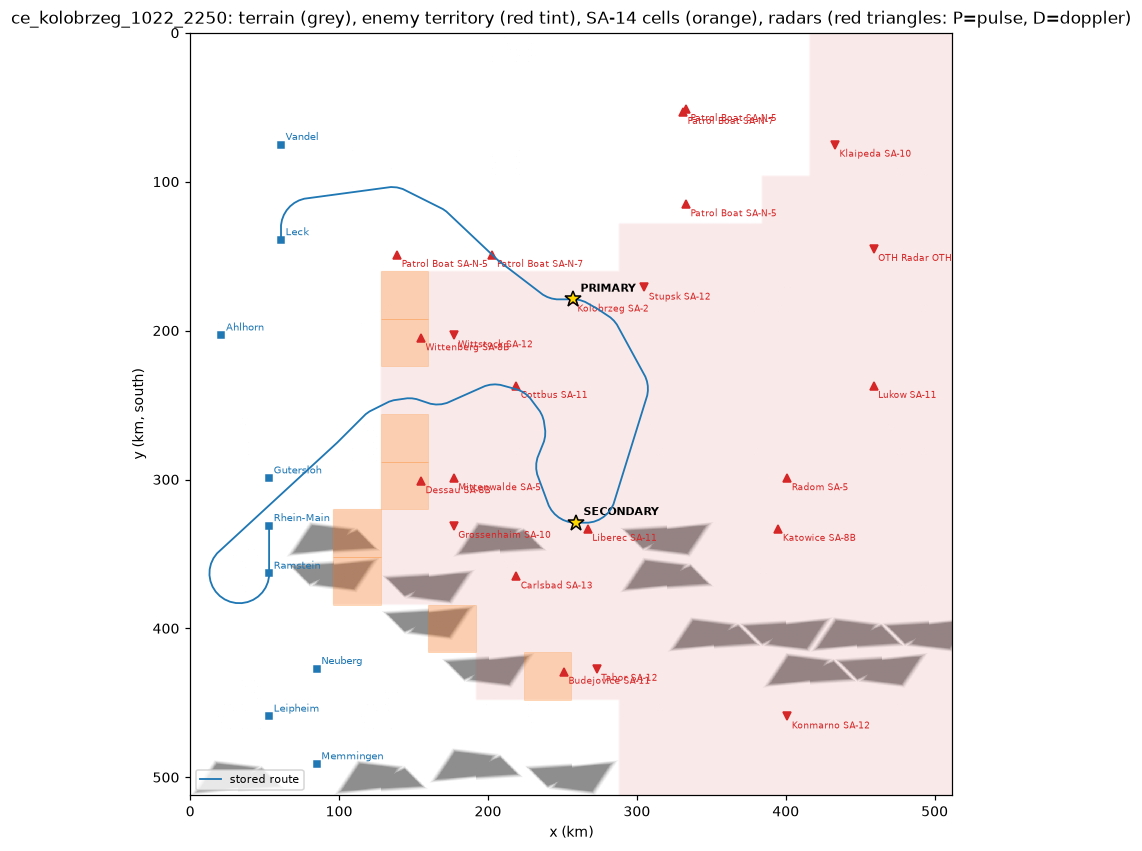

In [9]:
W = pl.W
print(f"theater {W.th}; terrain {W.H.shape} px at {W.step} units = {W.step/K:.2f} km/px; map {W.size/K:.0f} km square")
print(f"walls: {W.wall.mean():.1%} of the map; search grid {W.n}x{W.n} cells of {CELL_KM} km")
print(f"opponent index {W.opp} (0 green .. 3 elite), night={W.night}, sa14_hard={W.sa14_hard}, live SA-14 cells: {int(W.sa14_cells.sum())}")
print("airbases:", ", ".join(W.airbases))
print(f"{len(W.radars)} radars; takeoff/landing:", spec["takeoff"], "->", spec["landing"])

fig, ax = show_map(f"{PLAN}: terrain (grey), enemy territory (red tint), SA-14 cells (orange), radars (red triangles: P=pulse, D=doppler)",
                   routes=[dict(pts=stored["points"], color="C0", lw=1.2, label="stored route")])

### Territory grid bits

Each 32 km cell carries one byte. Decode it yourself:

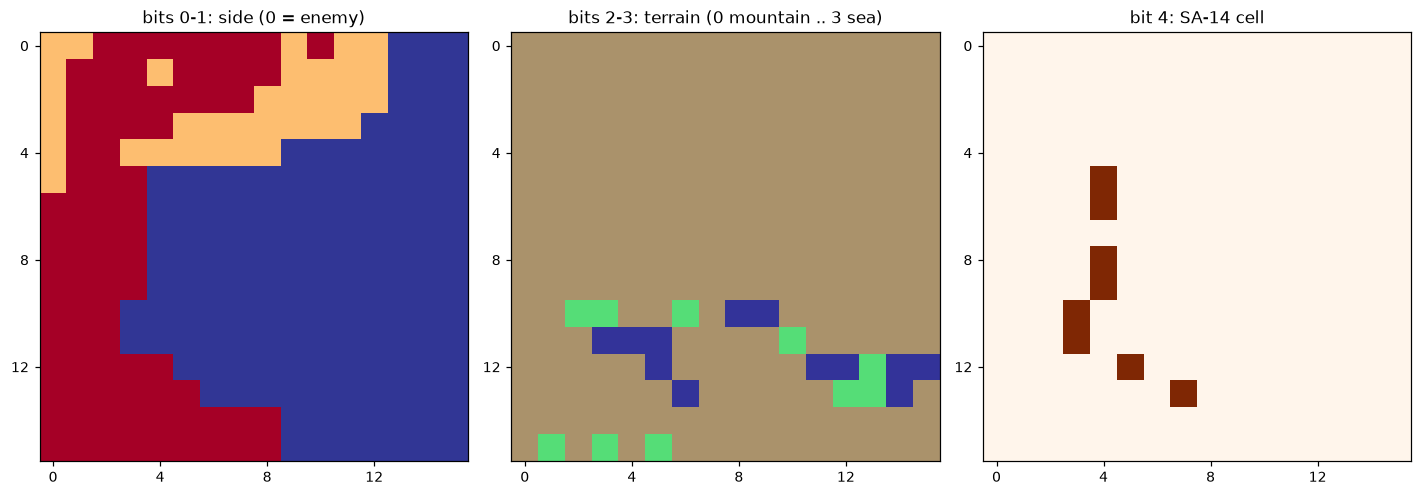

In [10]:
g = W.tgrid
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4))
axs[0].imshow(g & 3, cmap="RdYlBu_r", vmin=0, vmax=3); axs[0].set_title("bits 0-1: side (0 = enemy)")
axs[1].imshow((g >> 2) & 3, cmap="terrain", vmin=0, vmax=3); axs[1].set_title("bits 2-3: terrain (0 mountain .. 3 sea)")
axs[2].imshow((g & 0x10) > 0, cmap="Oranges"); axs[2].set_title("bit 4: SA-14 cell")
for a in axs: a.set_xticks(range(0, 16, 4)); a.set_yticks(range(0, 16, 4))
plt.tight_layout()

### Walls, clearance, and the planning margin

The route must stay `clear_km` (2 km) from any wall. Corridors are *searched* a further `plan_margin_km` (1.5 km) wider, because
20 km fillet arcs cut inside their corners. `World` precomputes both dilations, plus the blocked-cell mask for the 2 km search grid.
Zoom on a mountain area to see them:

point queries:  too_close at the target: False (targets may sit next to walls; the search exempts the ends)


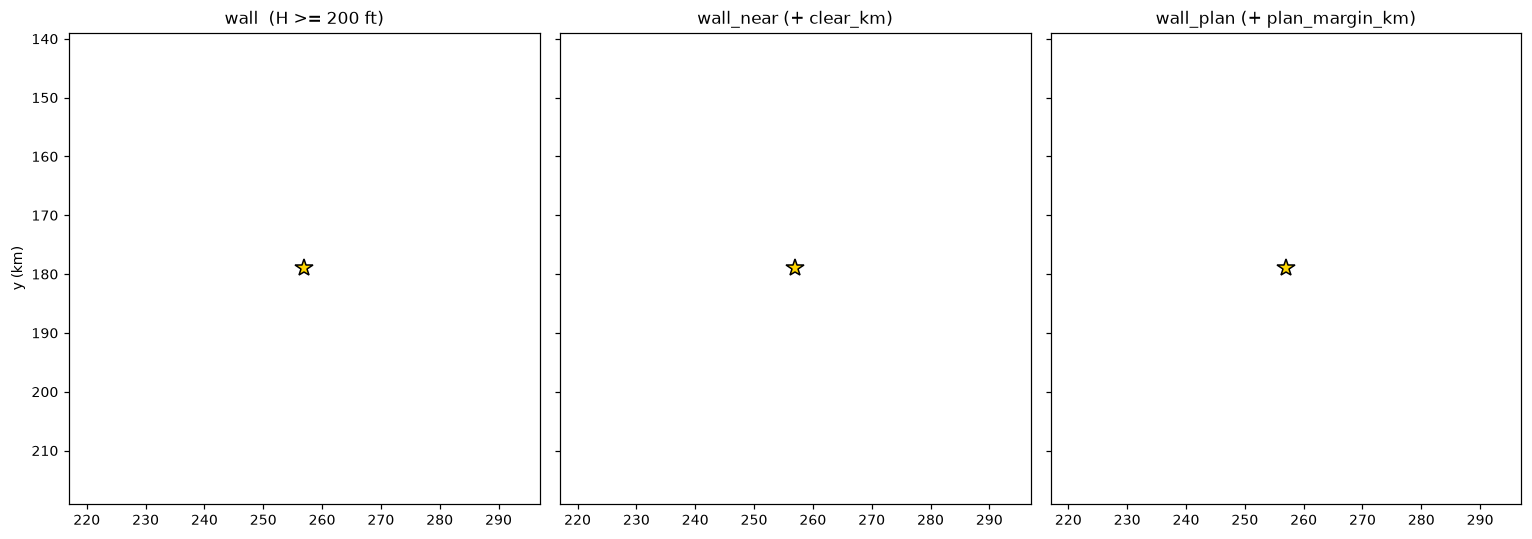

In [11]:
c = km(M["targets"][0]["x"]), km(M["targets"][0]["y"])
span = 40
x0, y0 = float(c[0]) - span, float(c[1]) - span
sl = (slice(int(y0 * K / W.step), int((y0 + 2 * span) * K / W.step)), slice(int(x0 * K / W.step), int((x0 + 2 * span) * K / W.step)))
ext = (x0, x0 + 2 * span, y0 + 2 * span, y0)
fig, axs = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
for ax, (name, m) in zip(axs, [("wall  (H >= 200 ft)", W.wall), ("wall_near (+ clear_km)", W.wall_near), ("wall_plan (+ plan_margin_km)", W.wall_plan)]):
    ax.imshow(m[sl], extent=ext, cmap="Greys", interpolation="nearest"); ax.set_title(name)
    ax.plot(*c, "*", c="gold", mec="k", ms=12)
axs[0].set_ylabel("y (km)")
plt.tight_layout()
print("point queries:  too_close at the target:", bool(W.too_close(M['targets'][0]['x'], M['targets'][0]['y'])), "(targets may sit next to walls; the search exempts the ends)")

## Step 3 · The radar model (`radar.py`, rules in `f19.rules.radar`)

What the planner believes about detection comes straight from the game's decoded code:

* a site's **return** `s` falls with range, depends on the site type and the opponent level, on the plane's **aspect** (pulse radars see
  the flank; dopplers see head-on and only when fast) and on the **terrain type of the plane's 32 km cell** (mountain ×0, rough ×0.5, flat ×1, sea ×1.5). *No terrain line of sight.*
* the plane's **EMV** (radar visibility) = altitude + |bank|/2 + speed/38 + 24 with the bay open + 16 with ECM.
* the plane is **seen** on a pulse when `s + EMV > 100`. The search uses a safer test, `margin = s + EMV - 100 > -radar_margin` (10).
* a quiet site pulses every 32 game s and is active ~37.5 % of the time, so **expected seen pulses per km** = sites seeing you × duty / 32 s × seconds per km.

In [12]:
RM = pl.RM
print("EMV (Elite = opp 3 in this plan; Veteran differs) by altitude and speed, wings level:")
print("alt ft \\ kt " + "".join(f"{k:>7d}" for k in (150, 190, 250, 350)))
for alt in (250, 700, 2000):
    print(f"{alt:10d}   " + "".join(f"{float(RM.emv(alt, kt)):7.0f}" for kt in (150, 190, 250, 350)))
print("\nbanked 12 deg in a 20 km turn, 700 ft, 190 kt:", float(RM.emv(700, 190, 12)), "| bay open:", float(RM.emv(700, 190, 0, True)))

EMV (Elite = opp 3 in this plan; Veteran differs) by altitude and speed, wings level:
alt ft \ kt     150    190    250    350
       250         9     11     12     15
       700        20     22     23     26
      2000        40     42     43     46

banked 12 deg in a 20 km turn, 700 ft, 190 kt: 26.0 | bay open: 46.0


In [13]:
kinds = sorted({(r["kind"], r["system"], r["type"]) for r in W.radars})
print("detection range (km) at which a site sees a 190 kt plane (flat ground, wings level):")
print(f"{'kind':>5s} {'system':10s} {'type':>4s}   {'700 ft radial':>13s} {'700 ft side':>12s} {'250 ft radial':>14s} {'250 ft side':>12s}")
for k, s, t in kinds:
    f = lambda asp, alt: RM.detection_range_km(k, asp, 190, alt=alt)
    fmt = lambda v: "never" if v is None else f"{v:.1f}"
    print(f"{k:5d} {s:10s} {t:>4s}   {fmt(f('radial',700)):>13s} {fmt(f('side',700)):>12s} {fmt(f('radial',250)):>14s} {fmt(f('side',250)):>12s}")

detection range (km) at which a site sees a 190 kt plane (flat ground, wings level):
 kind system     type   700 ft radial  700 ft side  250 ft radial  250 ft side
    1 SA-2          P           never         65.5          never         50.5
    2 SA-5          P           never         87.5          never         58.5
    3 SA-8B         P           never         54.5          never         46.5
    4 SA-10         D            85.5        never           51.5        never
    5 SA-11         P           never         87.5          never         75.5
    6 SA-12         D            61.5        never           27.5        never
    7 SA-13         P           never         40.5          never         31.5
    9 SA-N-5        P           never         48.5          never         37.5
   11 SA-N-7        P           never         87.5          never         75.5
   21 OTH           D            72.5        never           10.5        never


### Where would a plane be seen?

`RM.margins(x, y, ux, uy, kt, alt)` returns a (sites × points) array; broadcast it over the whole map to get
**how many sites see a 190 kt plane flying north / east at 700 ft vs 250 ft**. This is the radar picture the router prices.
Note how much 250 ft shrinks it, and how the answer depends on heading (aspect).

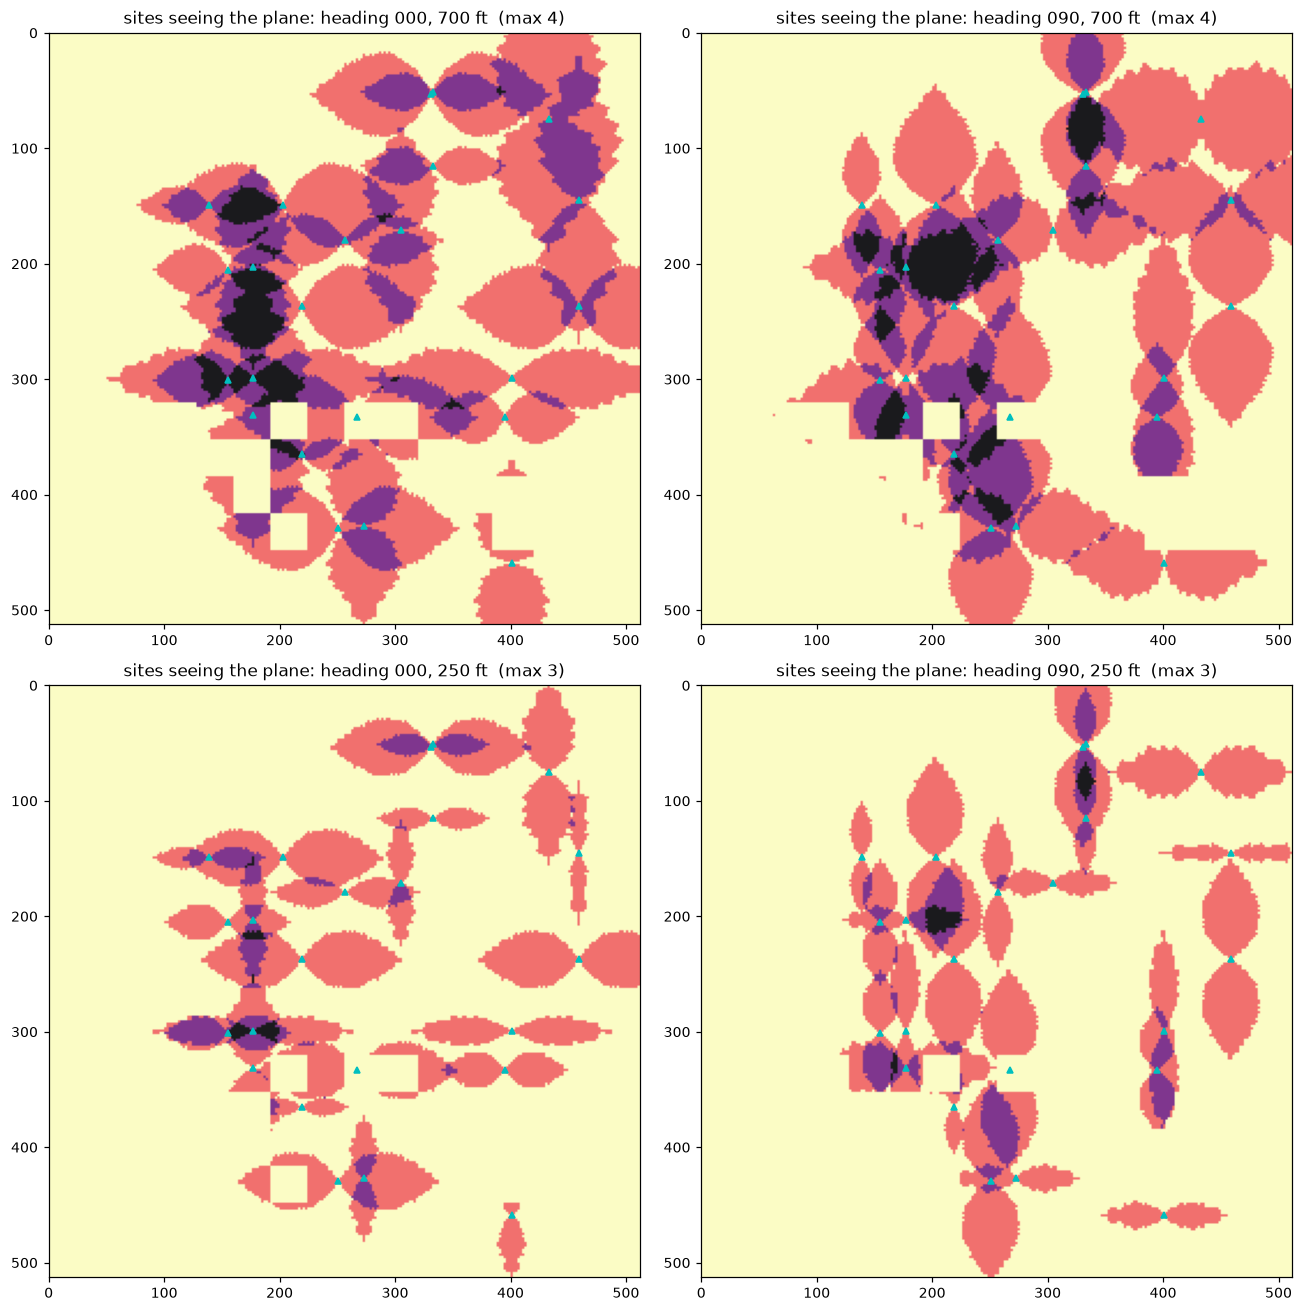

In [14]:
def seen_map(heading, alt, kt=190.0, step_km=2.0):
    n = int(W.size / K / step_km); c = (np.arange(n) + .5) * step_km * K
    X, Y = np.meshgrid(c, c); u = from_hdg(heading)
    return RM.seen_count(X, Y, u[0], u[1], kt, alt)

fig, axs = plt.subplots(2, 2, figsize=(12, 12))
L = W.size / K
for ax, (h, alt) in zip(axs.ravel(), [(0, 700), (90, 700), (0, 250), (90, 250)]):
    m = seen_map(h, alt)
    ax.imshow(m, extent=(0, L, L, 0), cmap="magma_r", vmin=0, vmax=3, alpha=.9)
    for r in W.radars: ax.plot(r["x"] / K, r["y"] / K, "c^", ms=4)
    ax.set_title(f"sites seeing the plane: heading {h:03d}, {alt} ft  (max {m.max()})")
plt.tight_layout()

`detection(...)` turns that count into **expected seen pulses per km** (count × 0.375 duty ÷ 32 s × seconds per km):

In [15]:
t = M["targets"][0]
pt = np.array([t["x"] - 25 * K, t["y"]])        # 25 km west of the primary target
for h in (0, 90, 180, 270):
    u = from_hdg(h)
    print(f"heading {h:3d}: seen by {int(RM.seen_count(pt[0], pt[1], u[0], u[1], 190, 250))} site(s) at 250 ft;"
          f" {float(RM.detection(pt[0], pt[1], u[0], u[1], 190, 250)):.4f} expected seen pulses/km")
print("\nsites in sight there (name, type, km, aspect, margin) flying east at 250 ft:")
for row in RM.in_sight(pt, from_hdg(90), 190, 250): print("  ", row)

heading   0: seen by 1 site(s) at 250 ft; 0.1521 expected seen pulses/km
heading  90: seen by 1 site(s) at 250 ft; 0.1521 expected seen pulses/km
heading 180: seen by 1 site(s) at 250 ft; 0.1521 expected seen pulses/km
heading 270: seen by 1 site(s) at 250 ft; 0.1521 expected seen pulses/km

sites in sight there (name, type, km, aspect, margin) flying east at 250 ft:
   ('Cottbus SA-11', 'P', 59.43904440685432, 'tangential', -3.0)


## Step 4 · Fuel, speed and the two regimes (`fuelplan.py`, rules in `f19.rules.fuel`)

Burn depends only on the throttle setting; speed depends on fuel weight, flaps, altitude and turn load. Score comes from
**cold-war samples** (one every 64 game s spent in an enemy cell), so the planner flies two regimes:

* **enemy cells** - the setting with the least **lb per minute** that holds level (usually 50 % + flaps): time there is worth points, fuel burned per sample is the price;
* **friendly / neutral cells** - the least **lb per km** (usually 70 % clean).

(`nav_hold_kt` / `nav_lb_min` in the profile then override the speed: the autopilot holds one airspeed, so the plan flies what the autopilot flies.)

In [16]:
reg = pl.regimes
print("settings that hold level at 6000 lb internal fuel, 700 ft:")
print(f"{'thr%':>5s} {'flaps':>6s} {'kt':>5s} {'lb/min':>7s} {'lb/km':>7s} {'stall kt':>9s}")
for s in sorted(reg.options(6000, 700), key=lambda s: (s.thr, s.flaps)):
    print(f"{s.thr:5d} {str(s.flaps):>6s} {s.kt:5d} {s.lb_min:7.1f} {s.lb_km:7.2f} {s.stall:9}")
e, t_ = reg.pick(True, 6000, 700), reg.pick(False, 6000, 700)
print(f"\nenemy pick   : {e.thr}% flaps={e.flaps} {e.kt} kt, {e.lb_min} lb/min")
print(f"transit pick : {t_.thr}% flaps={t_.flaps} {t_.kt} kt, {t_.lb_km:.2f} lb/km")
print(f"one cold-war sample = {reg.lb_per_sample(6000, 700):.0f} lb of fuel in the enemy regime")

settings that hold level at 6000 lb internal fuel, 700 ft:
 thr%  flaps    kt  lb/min   lb/km  stall kt
   50  False   184    60.0   13.41       121
   50   True   212    60.0   11.64        91
   60  False   276    75.0   11.17       121
   60   True   278    75.0   11.09        91
   70  False   344    90.0   10.76       121
   70   True   336    90.0   11.01        91
   80  False   405   120.0   12.18       121
   80   True   388   120.0   12.72        91

enemy pick   : 50% flaps=True 212 kt, 60 lb/min
transit pick : 50% flaps=True 212 kt, 11.64 lb/km
one cold-war sample = 64 lb of fuel in the enemy regime


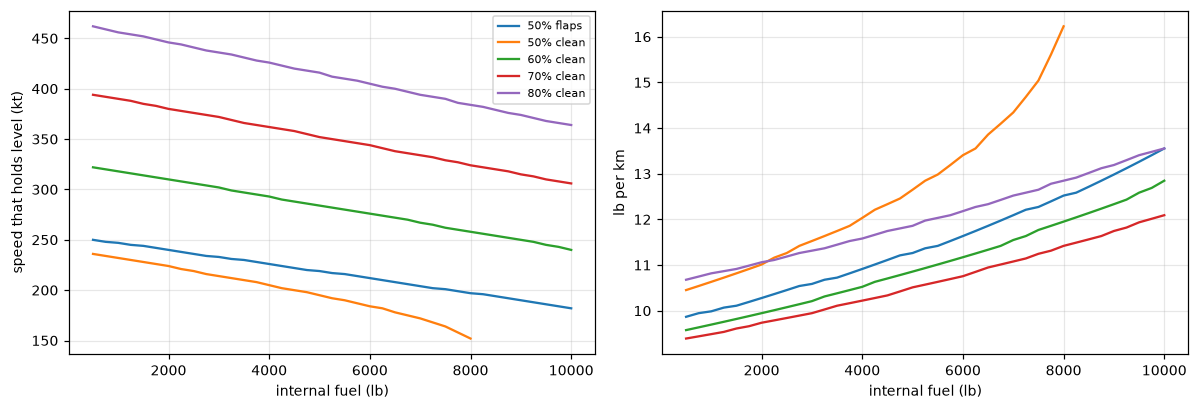

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
fuels = np.arange(500, 10001, 250)
for thr, flaps in [(50, True), (50, False), (60, False), (70, False), (80, False)]:
    kt, lbkm = [], []
    for f in fuels:
        o = [s for s in reg.options(f, 700) if s.thr == thr and s.flaps == flaps]
        kt.append(o[0].kt if o else np.nan); lbkm.append(o[0].lb_km if o else np.nan)
    ax[0].plot(fuels, kt, label=f"{thr}% {'flaps' if flaps else 'clean'}"); ax[1].plot(fuels, lbkm)
ax[0].set_ylabel("speed that holds level (kt)"); ax[1].set_ylabel("lb per km"); ax[0].legend(fontsize=7)
for a in ax: a.set_xlabel("internal fuel (lb)"); a.grid(alpha=.3)
plt.tight_layout()

## Step 5 · Pricing the grid (`Router.__init__`)

The router never looks at fuel or radar directly while searching: at construction it prices **every move on the 2 km grid, for
each of the 16 headings**, in one currency - **transit km** (the fuel one km of transit costs):

```
per km  = enemy_km (enemy cells cost more fuel per km) or 1
        + SA-14 minutes by day x sa14_cost_samples_per_min x sample_km
        + pulse_cost_samples x sample_km x expected seen pulses per km (the radar model above)
```

`router.cost[h]` is an array (one price per cell) for heading `MOVES[h]`. Plot it for four headings:

R = 20 km turn radius; one cold-war sample = 5.50 transit km; enemy km cost x1.00; one seen pulse = 55.0 km; 16 headings
black = cells the search may not enter (within clear_km + plan_margin_km of a wall)


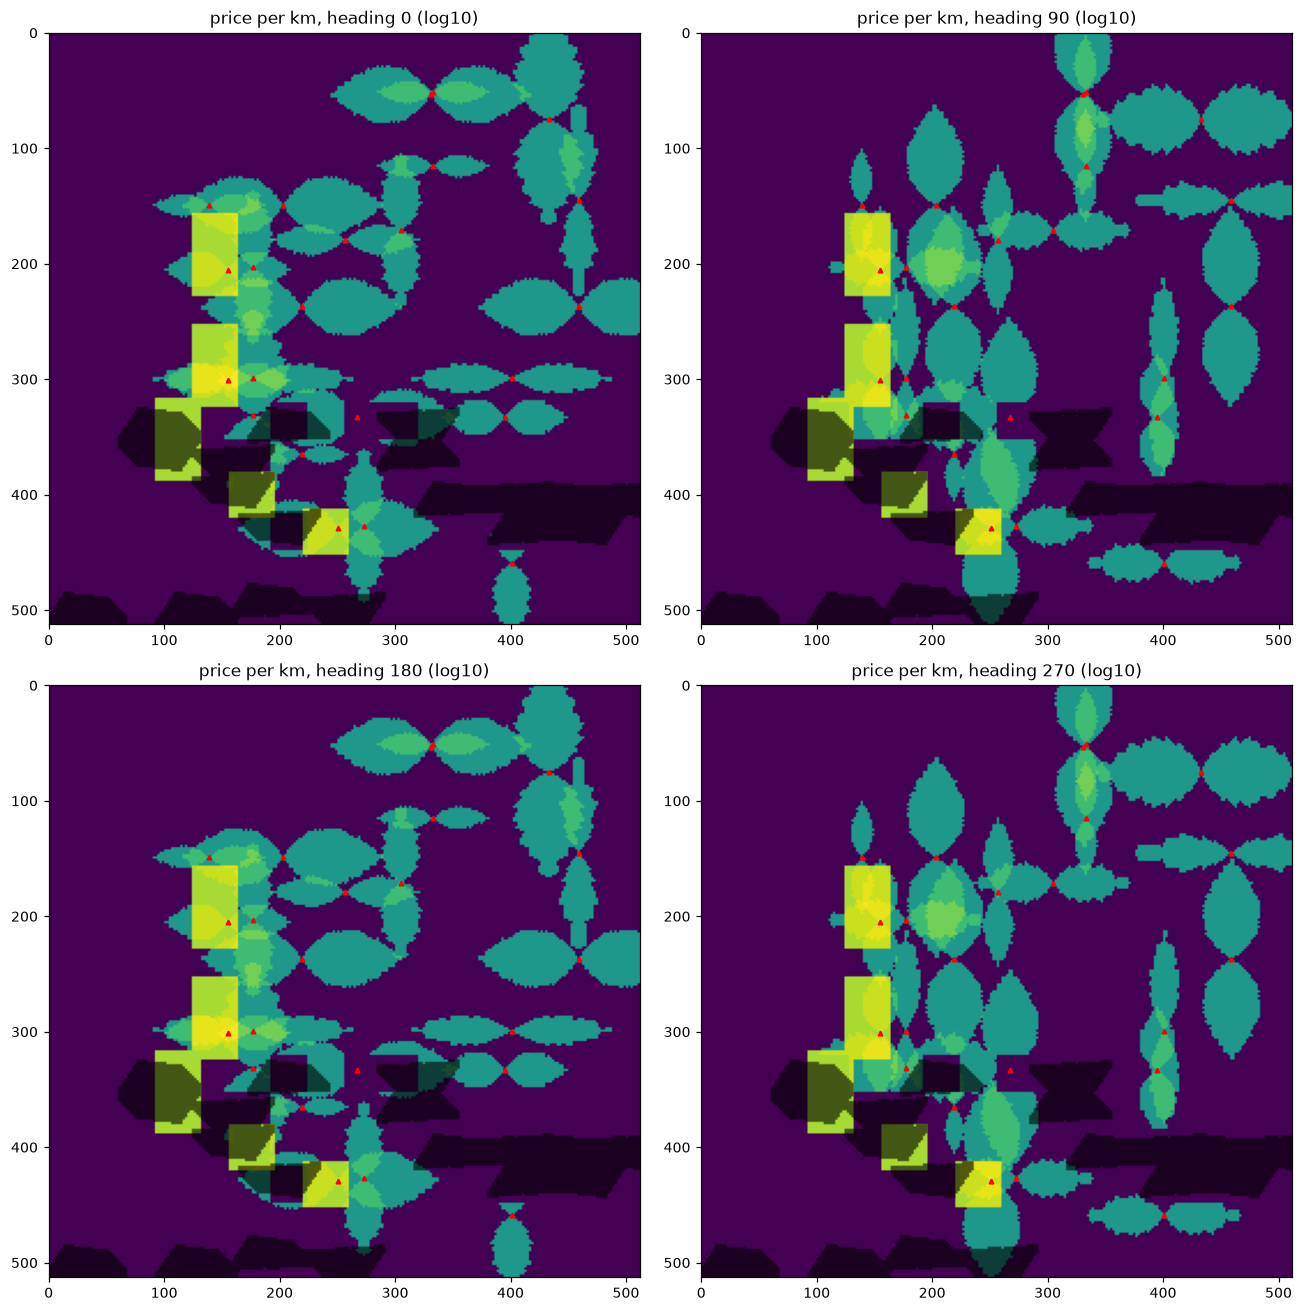

In [18]:
R_ = pl.router
print(f"R = {R_.R/K:.0f} km turn radius; one cold-war sample = {R_.sample_km:.2f} transit km; enemy km cost x{R_.enemy_km:.2f}; "
      f"one seen pulse = {R_.w_pulse:.1f} km; {len(MOVES)} headings")
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
for ax, h in zip(axs.ravel(), (0, 90, 180, 270)):
    k = nearest_dir(h); dx, dy = MOVES[k]; step_len = math.hypot(dx, dy) * CELL_KM
    c = R_.cost[k] / step_len                                    # price per km flown
    im = ax.imshow(np.log10(c), extent=(0, L, L, 0), cmap="viridis"); ax.set_title(f"price per km, heading {DIR_ANG[k]:.0f} (log10)")
    ax.imshow(np.where(W.blocked_plan, 1.0, np.nan), extent=(0, L, L, 0), cmap=ListedColormap(["k"]), alpha=.6)
    for r in W.radars: ax.plot(r["x"] / K, r["y"] / K, "r^", ms=3)
plt.tight_layout()
print("black = cells the search may not enter (within clear_km + plan_margin_km of a wall)")

Break the price into its parts at a few cells. A cell on friendly ground with no radar costs exactly 1.0 per km; the rest is what the profile says things are worth:

In [19]:
k = nearest_dir(90); dx, dy = MOVES[k]
cells = {"takeoff base": W.cell(W.airbases[spec["takeoff"]] if isinstance(spec["takeoff"], str) else (spec["takeoff"]["x"], spec["takeoff"]["y"])),
         "primary target": W.cell((M["targets"][0]["x"], M["targets"][0]["y"])),
         "secondary target": W.cell((M["targets"][1]["x"], M["targets"][1]["y"])) if len(M["targets"]) > 1 else None}
print(f"{'cell':18s} {'enemy?':>7s} {'price/km (E)':>13s}   what it is")
for name, cell in cells.items():
    if cell is None: continue
    j, i = cell
    print(f"{name:18s} {str(bool(W.enemy_grid[j,i])):>7s} {R_.cost[k][j,i]/(math.hypot(dx,dy)*CELL_KM):13.2f}")

cell                enemy?  price/km (E)   what it is
takeoff base         False          1.00
primary target        True         16.00
secondary target      True          1.00


## Step 6 · The mission skeleton (`Planner.takeoff / targets / landing / attack_piece`)

A route is a **sequence of elements**, some *fixed* (flown exactly as given, joined by arcs) and some free:

| element | kind | built by |
|---|---|---|
| takeoff + climb-out | fixed: runway north-south, climb 8 km on the game's takeoff heading | `pl.takeoff()` |
| target | `target` (a point to overfly) → replaced by an **attack piece** | `pl.targets(order)`, `pl.attack_piece(...)` |
| landing | fixed: Intercept → Approach fix → Final → Runway, on the N or S side | `pl.landing("N"/"S")` |

In [20]:
tg = {t["role"].rstrip("?"): t for t in pl.M["targets"]}
skel = [pl.takeoff(), *pl.targets(("primary", "secondary")), pl.landing("S")]
for el in skel:
    if el["t"] == "fixed":
        print("FIXED ", " -> ".join(f"{l or '·'} ({p[0]/K:.0f},{p[1]/K:.0f})" for p, l, _ in el["pts"]))
    else:
        print("TARGET", el["label"], f"({el['xy'][0]/K:.0f},{el['xy'][1]/K:.0f}) km", el["attrs"])
print("\nattack mode per target (from the briefing task):", {r: pl.attack_mode(t) for r, t in tg.items()})

FIXED  Takeoff (Leck) (61,139) -> Climb-out (61,131)
TARGET PRIMARY: SAM Radar Kolobrzeg (257,179) km {'kind': 'overfly', 'role': 'primary'}
TARGET SECONDARY: Tank Farm Liberec (259,329) km {'kind': 'overfly', 'role': 'secondary'}
FIXED  Intercept (53,363) -> Approach fix (53,351) -> Final (53,337) -> Landing (Rhein-Main) (53,331)

attack mode per target (from the briefing task): {'primary': ('photo', 'photograph mission'), 'secondary': ('photo', 'photograph mission')}


### Attack geometry

The *task* decides how a target is attacked: **photograph** → run-in, a photo point 0.7-2 km short, then over the target;
**destroy** → a Maverick launch 14 km short (after which the route is free); anything else → just overfly.
The approach **bearing** is free. `attack_piece(el, t, mode, bearing)` builds the fixed piece for one bearing
(or `None` if it would hit a wall / leave the map / enter an SA-14 cell). Here are the twelve 30° bearings around the primary:

PRIMARY run-in                             runin    photo run-in on 90: camera + SAM Radar Kolobrzeg selected, straight at it
PRIMARY: photo point 0.7 km                photo    PHOTO: bay open, nose on target, FIRE camera, bay closed
PRIMARY: SAM Radar Kolobrzeg               overfly  frame taken? then turn away


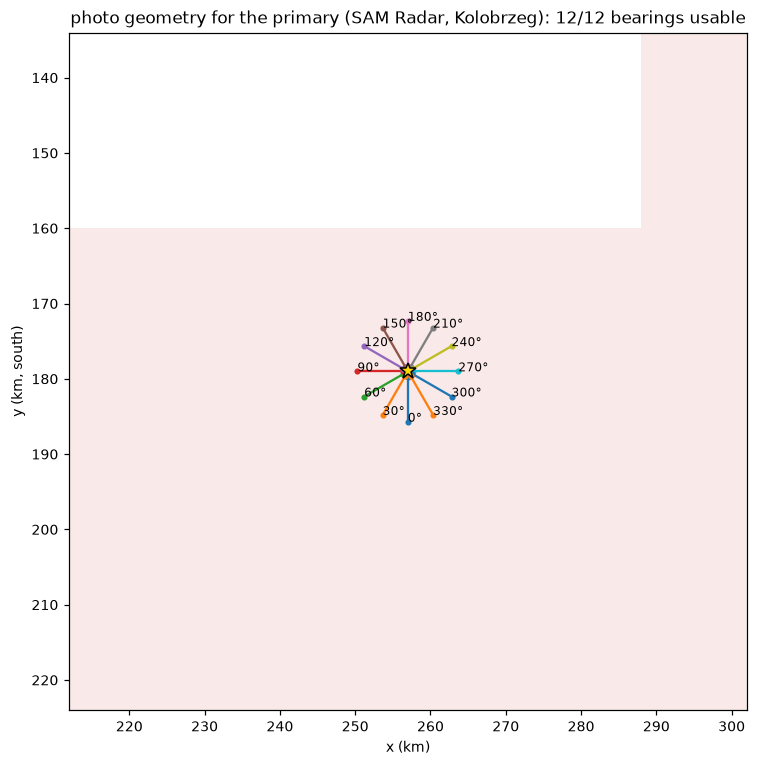

In [21]:
el = skel[1]; t0 = tg["primary"]; mode = pl.attack_mode(t0)[0]
cx, cy = t0["x"] / K, t0["y"] / K
fig, ax = plt.subplots(figsize=(8, 8))
draw_world(ax, pl, crop=(cx - 45, cx + 45, cy - 45, cy + 45), labels=False)
ok = 0
for b in range(0, 360, 30):
    pc = pl.attack_piece(el, t0, mode, float(b))
    if pc is None:
        u = from_hdg(b); q = np.array([cx, cy]) - u * 20
        ax.annotate(f"{b}°\nblocked", q, ha="center", color="r", fontsize=8); continue
    ok += 1; a = xy_of(pc["pts"]); ax.plot(a[:, 0], a[:, 1], "-o", ms=3, lw=1.5, label=f"{b}°")
    ax.annotate(f"{b}°", a[0], fontsize=8)
ax.set_title(f"{mode} geometry for the primary ({t0['object']}, {t0['place']}): {ok}/12 bearings usable")
for p, l, a in pl.attack_piece(el, t0, mode, 90.0)["pts"] if pl.attack_piece(el, t0, mode, 90.0) else []:
    print(f"{l:42s} {a['kind']:8s} {a['action']}")

### Which bearings are worth planning? `attack_options` **(slow, ~30 s)**

For every usable bearing the planner searches and joins the stretch *previous piece → attack piece → next piece* with the real minimum-radius geometry
and prices it (`attack_options`). The cheapest `attack_candidates` (2) bearings go into the full option product. The ranking is written to `pl.log`:

In [22]:
if RUN_SLOW:
    t = time.time()
    pieces = pl.attack_options(skel, 1, tg["primary"], pl.attack_mode(tg["primary"])[0])
    print(f"{time.time()-t:.0f} s;", "kept bearings:", [p["bearing"] for p in pieces])
    print(pl.log[-1])
else:
    print("RUN_SLOW is False. The stored report lists what was chosen:", stored["chosen"])

RUN_SLOW is False. The stored report lists what was chosen: order primary/secondary, approach S, primary photo on 90, secondary photo on 270


## Step 7 · Routing: from a sequence to a flyable path (`router.py`)

`Planner.plan(seq)` turns one sequence into one route. For each pair of neighbours it runs the router's stages, then joins everything:

1. **search** - A\* on the 2 km grid with *heading states* (it may change heading one step per move; the state remembers km flown since the last turn so a valley the search threads can really be flown at R). Decides the **topology**: which side of each radar and mountain.
2. **reduce** - exact DP over the search path: the *fewest corners* whose straight legs stay wall-clear, minimising leg cost + corner cost.
3. **expand** - fixed pieces keep their headings; they are joined to free corners by arc + straight, and to each other by Dubins arc + straight + arc, all at R.
4. **repair** - every corner becomes a fillet of radius R, needing `R·tan(turn/2)` of straight on each side. Where a leg is too short the planner drops, merges or pushes corners (cheapest first).
5. **densify** - arcs sampled every ~4 km.
6. **validate** - an independent check: turns flyable at R, terrain clear, targets overflown, SA-14 rule.

The cell below is `Planner.plan()` with the intermediate results kept, so you can look at each stage.

In [23]:
def plan_verbose(pl, seq, ends=None):
    """Planner.plan() up to the dense route, returning every stage's output."""
    Rt = pl.router; legs = []; core, h_arr = [seq[0]], None
    clip = lambda p: tuple(np.clip(p, 64, pl.W.size - 64))
    for A, B in zip(seq, seq[1:]):
        if A["t"] == "fixed": start, h0 = A["pts"][-1][0], hdg(unit(np.subtract(A["pts"][-1][0], A["pts"][-2][0])))
        else: start, h0 = A["xy"], h_arr
        if B["t"] == "fixed": end, hg = B["pts"][0][0], hdg(unit(np.subtract(B["pts"][1][0], B["pts"][0][0])))
        else: end, hg = B["xy"], None
        path, h_arr = Rt.search(clip(start), clip(end), h0, hg)      # 1. search
        red = Rt.reduce(path)                                         # 2. reduce
        legs.append(dict(start=start, end=end, h0=h0, hg=hg, search=path, reduced=red))
        core += [dict(t="v", xy=tuple(p)) for p in red] + [B]
    V0 = Rt.expand(core, ends); viol0 = Rt.violations(V0, ends)       # 3. expand (before any repair)
    log = []
    core, V = Rt.repair(core, log, ends)                              # 4. repair
    dense = Rt.densify(V)                                             # 5. densify
    return dict(legs=legs, V0=V0, viol0=viol0, repair_log=log, V=V, dense=dense)

seq = chosen_sequence(pl, stored["chosen"])
t = time.time(); pv = plan_verbose(pl, seq); print(f"{time.time()-t:.1f} s")
print(f"{len(pv['legs'])} legs between {len(seq)} elements;",
      "search points per leg:", [len(l['search']) for l in pv['legs']], "-> corners kept by reduce:", [len(l['reduced']) for l in pv['legs']])
print(f"expand: {len(pv['V0'])} vertices, {len(pv['viol0'])} violations before repair; repair actions: {pv['repair_log'] or 'none needed'}")
print(f"after repair: {len(pv['V'])} vertices; densified to {len(pv['dense'])} points")

3.0 s
3 legs between 4 elements; search points per leg: [77, 58, 168] -> corners kept by reduce: [4, 3, 10]
expand: 79 vertices, 0 violations before repair; repair actions: none needed
after repair: 79 vertices; densified to 145 points


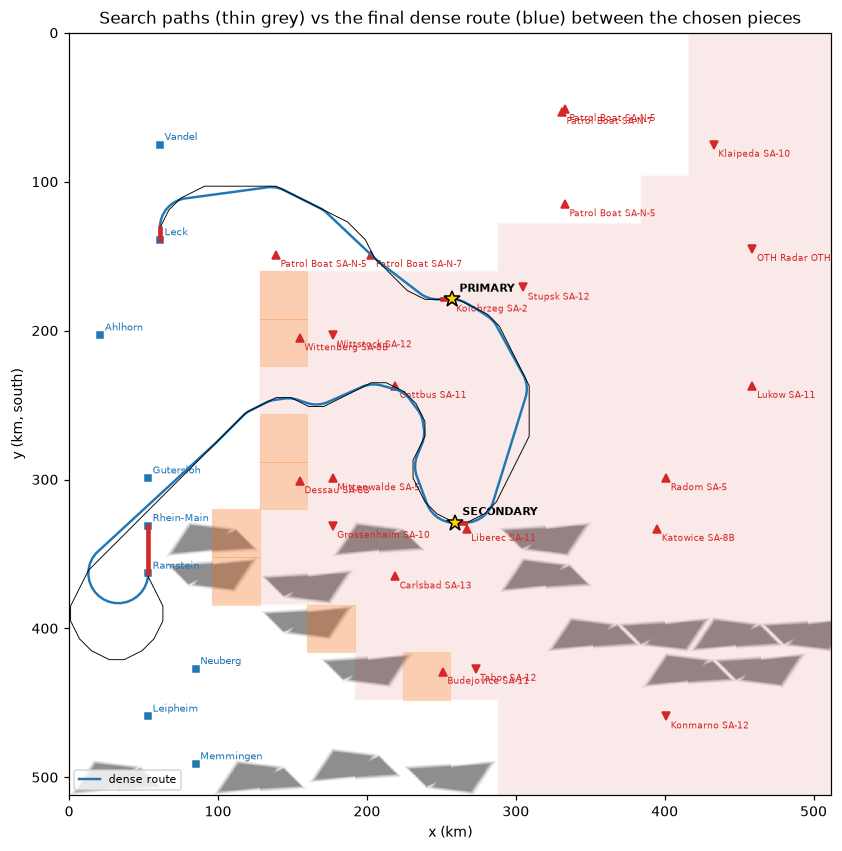

In [24]:
fig, ax = show_map("Search paths (thin grey) vs the final dense route (blue) between the chosen pieces",
                   routes=[dict(pts=pv["dense"], color="C0", lw=1.6, label="dense route")])
for lg in pv["legs"]: draw_route(ax, lg["search"], color="k", lw=.6)
for k, el in enumerate(seq):
    if el["t"] == "fixed": draw_route(ax, el["pts"], color="C3", lw=3)

### Zoom into one leg, stage by stage

Pick a leg with `LEG` (0 = takeoff → first target's run-in). The four panels are the stage outputs for that leg only.
The background is the router's price for the leg's mean heading, so you can see *why* the search bends where it does.

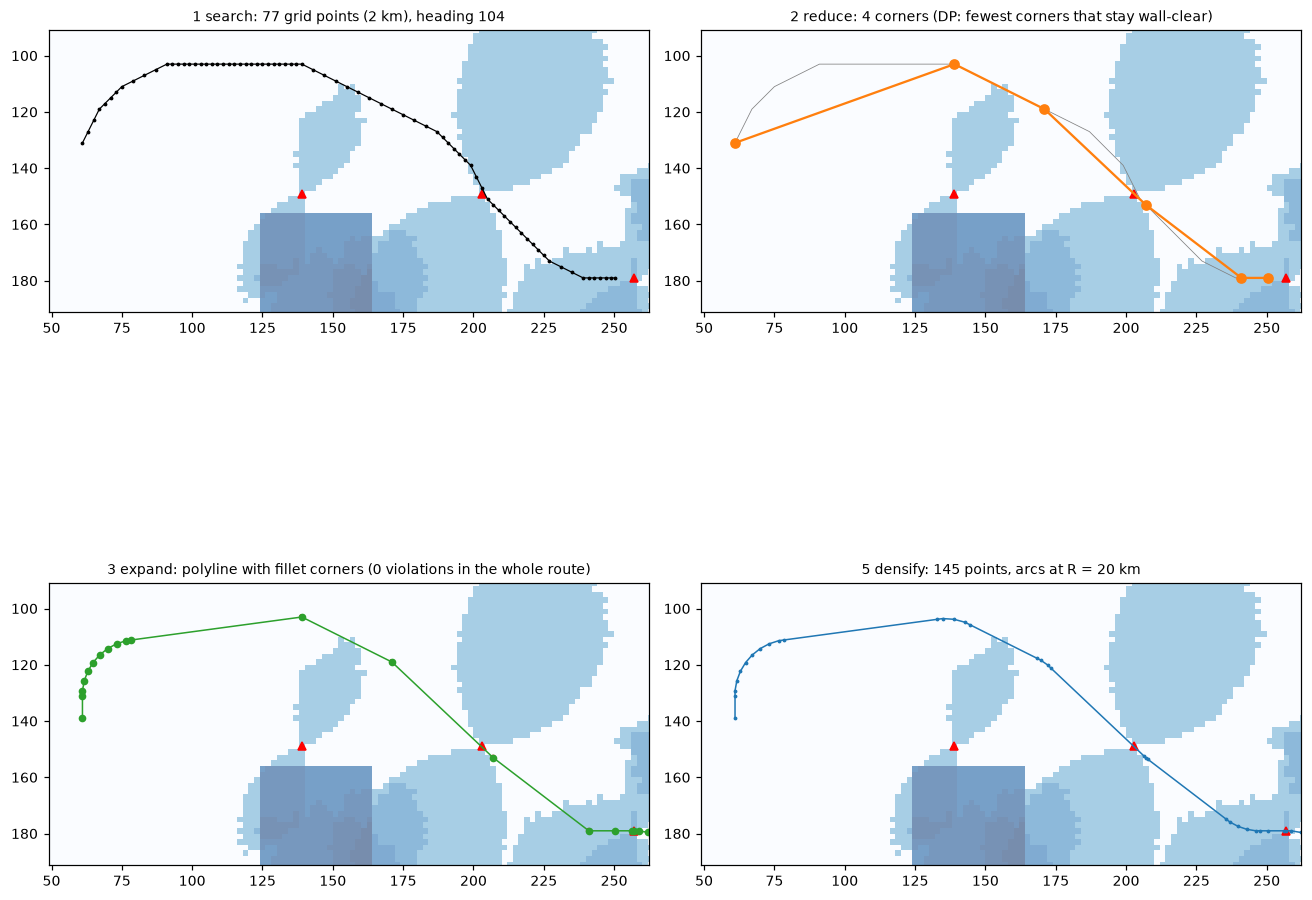

In [25]:
LEG = 0
lg = pv["legs"][LEG]
box = bbox_of(lg["search"], 12)
mean_h = hdg(np.subtract(lg["end"], lg["start"]))
kk = nearest_dir(mean_h)
price = R_.cost[kk] / (math.hypot(*MOVES[kk]) * CELL_KM)

def panel(ax, title):
    ax.imshow(np.log10(price), extent=(0, L, L, 0), cmap="Blues", alpha=.55)
    ax.imshow(np.where(W.blocked_plan, 1.0, np.nan), extent=(0, L, L, 0), cmap=ListedColormap(["k"]), alpha=.55)
    ax.set_xlim(box[0], box[1]); ax.set_ylim(box[3], box[2]); ax.set_aspect("equal"); ax.set_title(title, fontsize=9)
    for r in W.radars: ax.plot(r["x"] / K, r["y"] / K, "r^", ms=5)

fig, axs = plt.subplots(2, 2, figsize=(12, 12))
a = xy_of(lg["search"]); panel(axs[0, 0], f"1 search: {len(a)} grid points (2 km), heading {mean_h:.0f}")
axs[0, 0].plot(a[:, 0], a[:, 1], ".-", c="k", ms=3, lw=.8)

b = xy_of([lg["start"], *lg["reduced"], lg["end"]]); panel(axs[0, 1], f"2 reduce: {len(lg['reduced'])} corners (DP: fewest corners that stay wall-clear)")
axs[0, 1].plot(a[:, 0], a[:, 1], "-", c="grey", lw=.5); axs[0, 1].plot(b[:, 0], b[:, 1], "o-", c="C1", ms=6)

Vx = np.array([v["xy"] for v in pv["V0"]]) / K; panel(axs[1, 0], f"3 expand: polyline with fillet corners ({len(pv['viol0'])} violations in the whole route)")
axs[1, 0].plot(Vx[:, 0], Vx[:, 1], "o-", c="C2", ms=4, lw=1)
for v in pv["V0"]:
    if v["fillet"]: axs[1, 0].add_patch(Circle(v["xy"] / K, 0.8, fc="none", ec="C3"))

d = xy_of(pv["dense"]); panel(axs[1, 1], f"5 densify: {len(pv['dense'])} points, arcs at R = {R_.R/K:.0f} km")
axs[1, 1].plot(d[:, 0], d[:, 1], ".-", c="C0", ms=3, lw=1)
plt.tight_layout()

### The fillet rule: why legs can't be too short

A corner of `turn` degrees at radius R needs `R·tan(turn/2)` of straight leg on each side of the vertex (`Router.tangents`).
Two adjacent corners need their tangents to fit in the leg between them; otherwise `violations()` reports `short`, and `repair` has to drop or merge a corner.

In [26]:
Rkm = R_.R / K
print(f"R = {Rkm:.0f} km")
print(f"{'turn':>6s} {'tangent km':>11s} {'arc km':>8s}")
for turn in (10, 20, 30, 45, 60, 90, 120, 150):
    print(f"{turn:6d} {Rkm*math.tan(math.radians(turn)/2):11.1f} {Rkm*math.radians(turn):8.1f}")
t_ = R_.tangents(pv["V"])
print("\nin the final route: biggest tangent", max(t_) / K, "km;  legs:", len(pv["V"]) - 1, " violations left:", len(R_.violations(pv["V"])))

R = 20 km
  turn  tangent km   arc km
    10         1.7      3.5
    20         3.5      7.0
    30         5.4     10.5
    45         8.3     15.7
    60        11.5     20.9
    90        20.0     31.4
   120        34.6     41.9
   150        74.6     52.4

in the final route: biggest tangent 8.460966594281535 km;  legs: 78  violations left: 0


### Validation, and the whole thing as one call

`validate` re-checks the dense route independently of how it was built (bugs in `expand`/`repair` can't hide). `Planner.plan(seq)` then adds fuel
integration (next step) and returns the dict that everything downstream consumes. It must give the same cost as our step-by-step version:

In [27]:
overfly = {e["label"] for e in seq if e["t"] == "target"} | {l for e in seq for l in e.get("overfly_labels", ())}
mav = {e["role"] for e in seq if e.get("attack") == "maverick"}
errs = R_.validate(pv["dense"], [t for t in pl.M["targets"] if t["role"].rstrip("?") not in mav], overfly)
print("validate errors:", errs or "none")
t = time.time(); r = pl.plan(seq); print(f"pl.plan(seq): {time.time()-t:.1f} s; errors={r['errors'] or 'none'}; cost {r['cost']:.1f} (stored: {stored['summary']['cost']})")
print("keys:", list(r))
print("route cost from our pieces:", round(R_.route_cost(pv['V']) + pl.bay_cost(r['pts']), 1))

validate errors: none


pl.plan(seq): 0.7 s; errors=none; cost 1510.0 (stored: 1510.0)
keys: ['seq', 'V', 'pts', 'cost', 'errors', 'log', 'fuel']
route cost from our pieces: 1510.0


## Step 8 · Fuel, altitude and time along the route (`fuelplan.integrate`)

The dense route is walked in **1 km steps** in game time, three passes, because altitude, speed, radar and fuel depend on each other:

1. **altitude** - 700 ft (`cruise_ft`, fuel-optimal) unless a site would see the plane there, then 250 ft (`threat_ft`) from 6 km before to 6 km after; high gaps under 15 km stay low. At Elite the plane flies low over *all* enemy ground (fighters can be anywhere).
2. **regime** by cell side (enemy / not), then a **radar override**: where a site still sees the plane but a slower setting that holds level wouldn't, slow down (padded 5 km each way).
3. **integrate** fuel and time; transfer an Extra Fuel tank (+1900 lb) whenever internal fuel falls under 500 lb; mark the **bay-open windows** (+24 EMV) before photo / launch points.

Each step is a dict: position, heading, km, bank, altitude, time, fuel, kt, throttle, flaps, enemy?, bay?, override?

953 one-km steps; fuel at takeoff 13800 lb, at landing 1694 lb, 195 game min, 236 steps slowed by a radar override
transfers: [('153 min', '707 km'), ('184 min', '849 km')]

example step: {'km': 1.0, 'bank': 0.0, 'alt': 250.0, 'leg': 25, 'loiter': False, 'label': '', 't': 2492.9, 'fuel': 7419.9, 'kt': 190, 'thr': 50, 'flaps': True, 'lb_min': 62.1, 'enemy': False, 'bay': False, 'override': False}


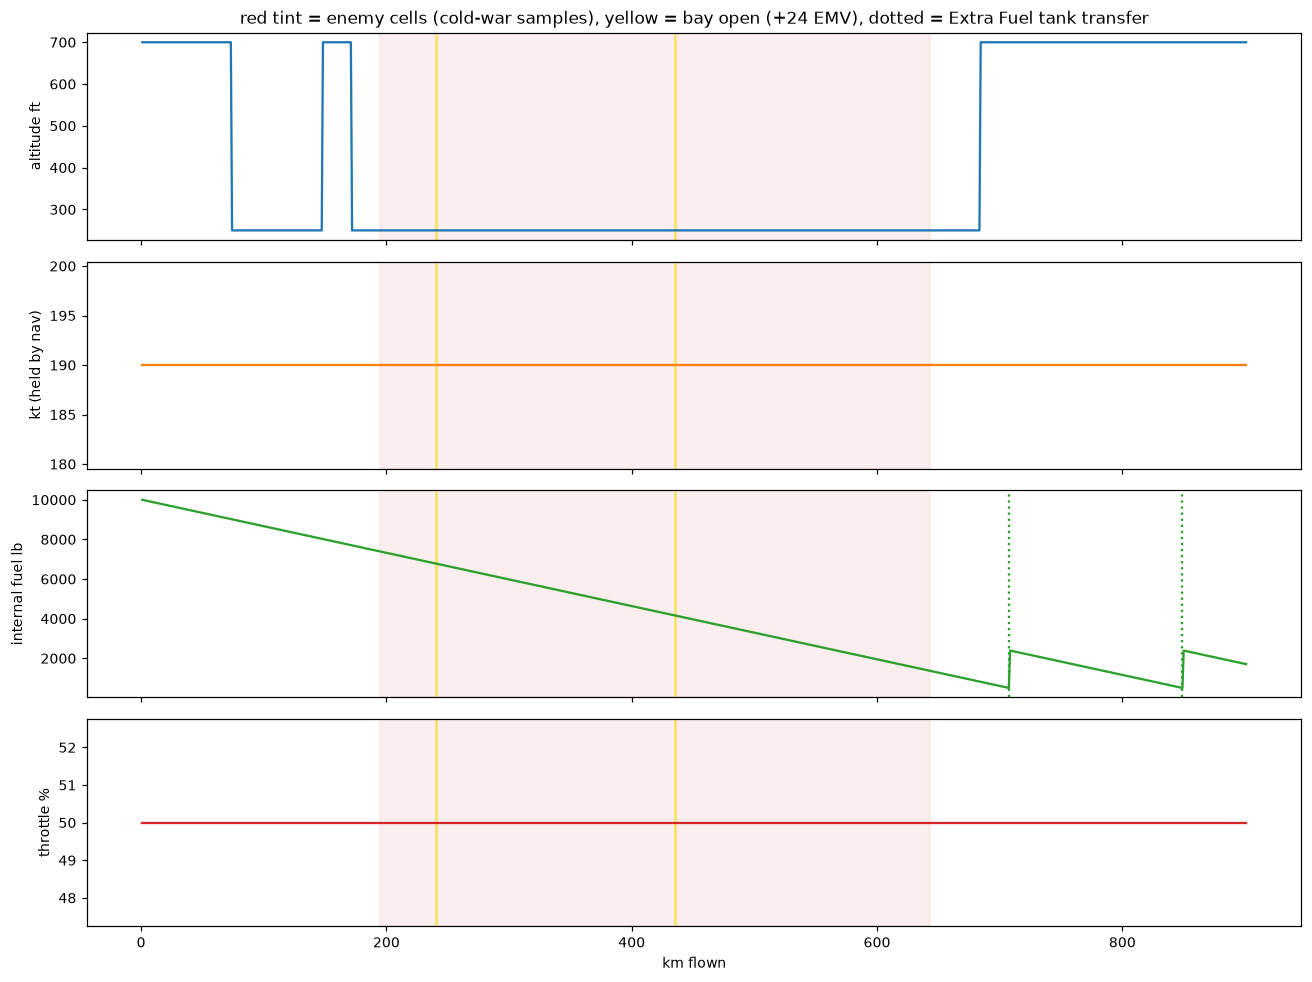

In [28]:
fu = r["fuel"]; steps = fu["steps"]
print(f"{len(steps)} one-km steps; fuel at takeoff {fu['fuel0']:.0f} lb, at landing {fu['fuel_land']:.0f} lb, {fu['t_end']/60:.0f} game min, {fu['overrides']} steps slowed by a radar override")
print("transfers:", [(f"{x['t']/60:.0f} min", f"{x['km']:.0f} km") for x in fu["transfers"]])
print("\nexample step:", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in steps[200].items() if k not in ("xy", "u")})

cum = np.cumsum([s["km"] for s in steps])
fig, axs = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
enemy = np.array([s["enemy"] for s in steps]); bay = np.array([s["bay"] for s in steps])
for a in axs:
    a.fill_between(cum, 0, 1, where=enemy, transform=a.get_xaxis_transform(), color="#d62728", alpha=.08)
    a.fill_between(cum, 0, 1, where=bay, transform=a.get_xaxis_transform(), color="gold", alpha=.5)
axs[0].plot(cum, [s["alt"] for s in steps], c="C0"); axs[0].set_ylabel("altitude ft")
axs[1].plot(cum, [s["kt"] for s in steps], c="C1"); axs[1].set_ylabel("kt (held by nav)")
axs[2].plot(cum, [s["fuel"] for s in steps], c="C2"); axs[2].set_ylabel("internal fuel lb")
for x in fu["transfers"]: axs[2].axvline(x["km"], c="C2", ls=":")
axs[3].plot(cum, [s["thr"] for s in steps], c="C3"); axs[3].set_ylabel("throttle %"); axs[3].set_xlabel("km flown")
axs[0].set_title("red tint = enemy cells (cold-war samples), yellow = bay open (+24 EMV), dotted = Extra Fuel tank transfer")
plt.tight_layout()

**Try it:** re-integrate the same points with a different profile. For example without the autopilot's held speed
(`nav_hold_kt=None`: the fuel model's own speeds), or with `burn_factor=1.1`:

In [29]:
for name, ov in {"as planned": {}, "no nav speed hold": {"nav_hold_kt": None}, "burn x1.1": {"burn_factor": 1.1}, "cruise high (no 250 ft)": {"threat_ft": 700.0}}.items():
    P2 = {**pl.P, **ov}
    bays = {l for p, l, a in r["pts"] if a.get("kind") in ("photo", "launch")}
    f2 = fuelplan.integrate(pl.W, pl.RM, P2, r["pts"], bays)
    print(f"{name:24s} landing fuel {f2['fuel_land']:7.0f} lb   time {f2['t_end']/60:6.1f} min   overrides {f2['overrides']}")

as planned               landing fuel    1694 lb   time  194.9 min   overrides 236
no nav speed hold        landing fuel    3373 lb   time  173.8 min   overrides 239


burn x1.1                landing fuel     484 lb   time  194.9 min   overrides 256


cruise high (no 250 ft)  landing fuel    1694 lb   time  194.9 min   overrides 353


## Step 9 · The alert simulation (`alertsim.py`)

The router priced radar exposure in expectation. For the *report*, every site is simulated **pulse by pulse** with the game's rules:
seen pulses raise the site's alert (+48 at Veteran, −16 unseen); alert > 0x7F raises every site (network alert); a **SAM launch** is possible at alert > 0xC0
(inside the SAM's range, > 20 km from a friendly field); a **radar ID** at ≥ 0xFA. The unknowns (each site's pulse phase, the frame counter) are drawn 48 times with a fixed seed,
in two modes: *worst* (sites always on) and *expected* (duty windows).

In [30]:
t = time.time(); sim = alertsim.simulate(pl.W, pl.RM, steps); print(f"{time.time()-t:.1f} s")
print("summary:", json.dumps(sim["summary"], indent=1))
print(f"\n{'site':26s} {'kind':>4s} {'best margin':>11s} {'seen/near steps':>16s} {'max alert (w/e)':>16s} {'P(launch)':>10s} {'P(ID)':>6s}")
for s in sorted(sim["sites"], key=lambda s: -s["best_margin"])[:10]:
    print(f"{s['name']:26s} {s['type']:>4s} {s['best_margin']:+11.0f} {s['seen_steps']:7d}/{s['near_steps']:<7d} "
          f"{s['worst']['max_alert']:7d}/{s['expected']['max_alert']:<7d} {s['expected']['p_launch']:10.0%} {s['expected']['p_id']:6.0%}")

1.6 s
summary: {
 "worst": {
  "p_any_net": 1.0,
  "p_any_launch": 1.0,
  "expected_ids": 1.8541666666666667,
  "max_alert": 255
 },
 "expected": {
  "p_any_net": 0.875,
  "p_any_launch": 0.3541666666666667,
  "expected_ids": 0.6875,
  "max_alert": 255
 }
}

site                       kind best margin  seen/near steps  max alert (w/e)  P(launch)  P(ID)
Cottbus SA-11                 P         +43      11/27          255/255            21%    29%
Stupsk SA-12                  D         +11       2/2           128/128             0%     0%
Patrol Boat SA-N-7            P          +7       1/5            64/64              0%     0%
Wittenberg SA-8B              P          +6       5/28          255/255            17%    29%
Mittenwalde SA-5              P          +3       7/24          255/255             6%    10%
Wittstock SA-12               D          -2       0/2            16/16              0%     0%
Patrol Boat SA-N-5            P          -5       0/6            16/16           

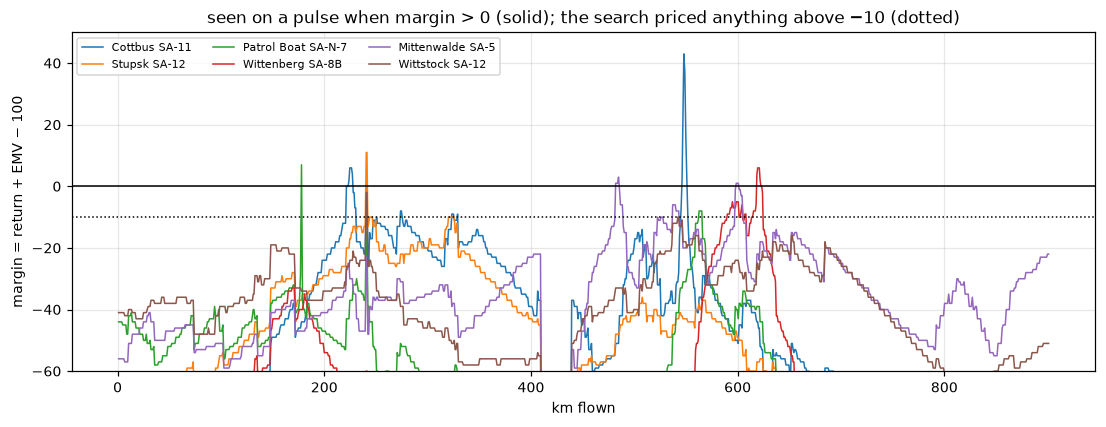

In [31]:
X = np.array([s["xy"][0] for s in steps]); Y = np.array([s["xy"][1] for s in steps])
U = np.array([s["u"] for s in steps]); kt = np.array([s["kt"] for s in steps], float)
alt = np.array([s["alt"] for s in steps]); roll = np.array([s["bank"] for s in steps]); bay_ = np.array([s["bay"] for s in steps])
Mg = pl.RM.margins(X, Y, U[:, 0], U[:, 1], kt, alt, roll, bay_)
top = np.argsort(-Mg.max(1))[:6]
fig, ax = plt.subplots(figsize=(12, 4))
for n in top: ax.plot(cum, Mg[n], lw=1, label=pl.RM.R[n][3])
ax.axhline(0, c="k", lw=1); ax.axhline(-pl.RM.M, c="k", ls=":", lw=1)
ax.set_ylim(-60, 50); ax.set_xlabel("km flown"); ax.set_ylabel("margin = return + EMV − 100")
ax.set_title("seen on a pulse when margin > 0 (solid); the search priced anything above −10 (dotted)"); ax.legend(fontsize=7, ncol=3); ax.grid(alpha=.3)

**Try it:** how much does altitude buy? Re-run the margins with the same route flown at 700 ft the whole way:

In [32]:
Mg700 = pl.RM.margins(X, Y, U[:, 0], U[:, 1], kt, np.full_like(alt, 700.0), roll, bay_)
print(f"steps with any site above margin 0:   as planned {int((Mg.max(0) > 0).sum()):4d}   all at 700 ft {int((Mg700.max(0) > 0).sum()):4d}")
print(f"steps with any site above margin -10: as planned {int((Mg.max(0) > -10).sum()):4d}   all at 700 ft {int((Mg700.max(0) > -10).sum()):4d}")

steps with any site above margin 0:   as planned   26   all at 700 ft  118
steps with any site above margin -10: as planned   89   all at 700 ft  451


## The math, end to end (steps 5-9 as equations)

The planner turns constraints into a route with **one objective and a few hard checks**. This section evaluates every formula by hand on the plan above and
asserts that it equals what the planner computes, so you can change a number and see which line moves.

| thing | how it enters |
|---|---|
| mountains, 2 km clearance | **hard**: blocked search cells, then `segment_clear` and `validate` |
| 20 km minimum turn radius | **hard**: the fillet condition `t_i + t_{i+1} ≤ L`, then `validate` |
| radar exposure | **price**: `w_pulse` transit km per expected seen pulse |
| SA-14 cells | **wall** at Elite by day, a **price** below that, free at night |
| turn count | **price**: `turn_simplicity_km` per corner |
| fuel reserve | **checked after** the route exists (an error, not a search constraint) |

### A · Exchange rates: everything is priced in *transit km*

In [33]:
from f19.planner.world import GROUND_KMH_PER_KT as KTK          # map km per game hour per indicated kt  (= 1.852 x 0.788)
from f19.planner.router import turn_deg
from f19.planner.fuelplan import TANK_LB, TRANSFER_BELOW

e_set = reg.pick(True,  P["fuel_ref_lb"], P["cruise_ft"])         # enemy regime: least lb/min
t_set = reg.pick(False, P["fuel_ref_lb"], P["cruise_ft"])         # transit regime: least lb/km
lb_per_sample = e_set.lb_min * P["sample_game_s"] / 60            # fuel burned in one 64 s cold-war sample
sample_km     = lb_per_sample / t_set.lb_km                       # ... expressed as km of transit
w_pulse       = P["pulse_cost_samples"] * sample_km               # one expected seen pulse
enemy_km      = e_set.lb_km / t_set.lb_km * (1 - R_.coldwar)      # an enemy-cell km costs this many transit km

print(f"enemy setting   {e_set.thr}% flaps={e_set.flaps}: {e_set.lb_min} lb/min, {e_set.lb_km:.2f} lb/km")
print(f"transit setting {t_set.thr}% flaps={t_set.flaps}: {t_set.lb_km:.2f} lb/km")
print(f"lb_per_sample = {e_set.lb_min} x {P['sample_game_s']:.0f}/60               = {lb_per_sample:.1f} lb")
print(f"sample_km     = {lb_per_sample:.1f} / {t_set.lb_km:.2f}                 = {sample_km:.2f} transit km")
print(f"w_pulse       = {P['pulse_cost_samples']:g} samples x {sample_km:.2f}          = {w_pulse:.1f} transit km per expected seen pulse")
print(f"enemy_km      = {e_set.lb_km:.2f} / {t_set.lb_km:.2f} x (1 - {R_.coldwar:g})   = {enemy_km:.2f}")
assert np.isclose(sample_km, R_.sample_km) and np.isclose(w_pulse, R_.w_pulse) and np.isclose(enemy_km, R_.enemy_km)
print("matches Router:", round(R_.sample_km, 2), round(R_.w_pulse, 1), round(R_.enemy_km, 2))

enemy setting   50% flaps=True: 60 lb/min, 11.64 lb/km
transit setting 50% flaps=True: 11.64 lb/km
lb_per_sample = 60 x 64/60               = 64.0 lb
sample_km     = 64.0 / 11.64                 = 5.50 transit km
w_pulse       = 10 samples x 5.50          = 55.0 transit km per expected seen pulse
enemy_km      = 11.64 / 11.64 x (1 - 0)   = 1.00
matches Router: 5.5 55.0 1.0


### B · The price of one km: `price = base + sa14 + w_pulse × detection`

with `detection = n_seen × duty / 32 s × (3600 / (kt × KTK))` expected seen pulses per km, and `n_seen` the number of sites whose
`margin = return + EMV − 100` exceeds −10. First a hand computation at the first point on the route where some site is in sight, compared with `Router.per_km`:

In [34]:
k0 = next(k for k, s in enumerate(steps) if int(RM.seen_count(*s["xy"], *s["u"], R_.kt_at(*s["xy"]))) > 0)
s0 = steps[k0]; x, y = s0["xy"]; ux, uy = s0["u"]
kt_ = float(R_.kt_at(x, y)); n = int(RM.seen_count(x, y, ux, uy, kt_))
s_per_km = 3600 / (kt_ * KTK)
det = n * RM.duty / 32 * s_per_km
jj, ii = W.cell((x, y))
base = enemy_km if W.enemy(x, y) else 1.0
sa = R_.sa14_pad[jj, ii] * R_.w_sa14 * 60 / (kt_ * KTK)
price = base + sa + w_pulse * det
print(f"point km {k0} ({x/K:.0f},{y/K:.0f}) heading {hdg((ux,uy)):.0f}: enemy cell={bool(W.enemy(x,y))}, kt={kt_:.0f}, {n} site(s) in sight")
print(f"seconds per km        = 3600 / ({kt_:.0f} x {KTK:.3f})            = {s_per_km:.2f}")
print(f"expected seen pulses  = {n} x {RM.duty} / 32 x {s_per_km:.2f}          = {det:.4f} per km")
print(f"price                 = {base:.2f} + {sa:.2f} + {w_pulse:.1f} x {det:.4f}  = {price:.2f} transit km per km")
print(f"Router.per_km         = {float(R_.per_km(x, y, ux, uy)):.2f}")
assert np.isclose(price, float(R_.per_km(x, y, ux, uy)))

point km 95 (132,104) heading 82: enemy cell=False, kt=212, 1 site(s) in sight
seconds per km        = 3600 / (212 x 1.459)            = 11.64
expected seen pulses  = 1 x 0.375 / 32 x 11.64          = 0.1364 per km
price                 = 1.00 + 0.00 + 55.0 x 0.1364  = 8.50 transit km per km
Router.per_km         = 8.50


In [35]:
print("what a site in sight costs, at this speed:")
for n_ in range(4):
    print(f"  {n_} site(s) seeing the plane: {base + w_pulse * n_ * RM.duty / 32 * s_per_km:6.2f} per km  =  x{(base + w_pulse * n_ * RM.duty / 32 * s_per_km) / base:.1f} a clean km")
print("\nchange w_pulse (the profile's pulse_cost_samples) and every detour decision moves with it: stealth 10, balanced 3, fast 0.5")

what a site in sight costs, at this speed:
  0 site(s) seeing the plane:   1.00 per km  =  x1.0 a clean km
  1 site(s) seeing the plane:   8.50 per km  =  x8.5 a clean km
  2 site(s) seeing the plane:  16.00 per km  =  x16.0 a clean km
  3 site(s) seeing the plane:  23.50 per km  =  x23.5 a clean km

change w_pulse (the profile's pulse_cost_samples) and every detour decision moves with it: stealth 10, balanced 3, fast 0.5


### C · The search: one move on the grid

`Router.cost[h][j, i]` is the price of flying one 2 km grid move on heading `MOVES[h]` out of cell `(j, i)`:
`length × 2 km × (base + w_pulse × detection at the cell centre)`. Plus a small turn penalty so the path doesn't zig-zag, and the
radius rule: after any heading change the plane must fly `2R·tan(13.3°)` before the next one. The heuristic that makes A\* fast and exact is straight-line distance × the cheapest possible price per km.

In [36]:
kk = nearest_dir(hdg((ux, uy))); dx, dy = MOVES[kk]; Lm = math.hypot(dx, dy)
cx_, cy_ = W.centre(jj, ii)
E_ = bool(W.enemy_grid[jj, ii]); kt_c = float(R_.e_set.kt if E_ else R_.t_set.kt)
u_ = (dx / Lm, dy / Lm)
base_c = (enemy_km if E_ else 1.0) + R_.sa14_pad[jj, ii] * R_.w_sa14 * 60 / (kt_c * KTK)
manual = Lm * CELL_KM * (base_c + w_pulse * float(RM.detection(cx_, cy_, u_[0], u_[1], kt_c)))
print(f"move {MOVES[kk]} (heading {DIR_ANG[kk]:.0f}, length {Lm:.2f} cells = {Lm*CELL_KM:.2f} km) from cell {(jj, ii)}")
print(f"cost by hand {manual:.3f}   Router.cost {R_.cost[kk][jj, ii]:.3f}")
assert np.isclose(manual, R_.cost[kk][jj, ii])

from f19.planner.router import SEARCH_TURN_KM_PER_DEG, NDIR
need = math.ceil(2 * R_.R / K * math.tan(math.radians(13.3)))
print(f"\n{NDIR} headings, {360/NDIR:.1f} deg apart; one heading change costs {360/NDIR*SEARCH_TURN_KM_PER_DEG:.2f} km")
print(f"after a turn: 2 R tan(13.3 deg) = 2 x {R_.R/K:.0f} x {math.tan(math.radians(13.3)):.3f} = {2*R_.R/K*math.tan(math.radians(13.3)):.1f} km -> {need} km before the next turn")
print(f"A* heuristic per km: min(1, enemy_km) = {R_.h_scale:.2f}  (no km can cost less than this, so it never overestimates)")
print(f"blocked cells: within clear_km + plan_margin_km = {P['clear_km'] + P['plan_margin_km']} km of a wall -> {int(W.blocked_plan.sum())} of {W.n*W.n} cells")

move (1, 0) (heading 90, length 1.00 cells = 2.00 km) from cell (51, 66)
cost by hand 2.000   Router.cost 2.000

16 headings, 22.5 deg apart; one heading change costs 2.25 km
after a turn: 2 R tan(13.3 deg) = 2 x 20 x 0.236 = 9.5 km -> 10 km before the next turn
A* heuristic per km: min(1, enemy_km) = 1.00  (no km can cost less than this, so it never overestimates)
blocked cells: within clear_km + plan_margin_km = 3.5 km of a wall -> 6497 of 65536 cells


### D · Reduce: dynamic programming over corners

`reduce` thins the grid path to every second cell and picks the subset of points that minimises

```
best[j] = min over i<j with segment i→j wall-clear of   best[i] + seg_cost(i, j) + corner_cost(i)
corner_cost = turn_simplicity_km + w_pulse × (detection banked 12° − detection level) × arc_km
```

`seg_cost` is the price integrated along the chord (1 km samples). So a corner costs 5 km plus whatever extra radar the banked arc adds.
Compare the raw search path with what the DP kept, on leg 0, using the same costs:

In [37]:
def poly_cost(poly):
    pts_ = [np.asarray(p, float) for p in poly]
    c = sum(R_.seg_cost(a, b) for a, b in zip(pts_, pts_[1:]))
    n_corners = 0
    for a, b, c2 in zip(pts_, pts_[1:], pts_[2:]):
        tdeg = turn_deg(a, b, c2)
        if tdeg > 2: c += R_.corner_cost(b, unit(b - a), tdeg); n_corners += 1
    return c, n_corners

lg = pv["legs"][0]
thin = [lg["search"][0]] + lg["search"][1:-1:2] + [lg["search"][-1]]
kept = [lg["search"][0], *lg["reduced"], lg["search"][-1]]
for name, poly in (("search path, every 2nd cell", thin), ("after reduce", kept)):
    c, nc = poly_cost(poly); print(f"{name:28s} {len(poly):3d} points, {nc:3d} corners, cost {c:7.1f} transit km")

def extra_at(a, p):                      # extra seen pulses per km of a banked arc vs level, at corner p arriving from a
    u = unit(np.asarray(p, float) - np.asarray(a, float)); k_ = float(R_.kt_at(*p))
    return float(RM.detection(p[0], p[1], u[0], u[1], k_, roll=P["turn_bank_deg"]) - RM.detection(p[0], p[1], u[0], u[1], k_))
cands = [(extra_at(l["search"][0] if j == 0 else l["reduced"][j - 1], p), p, l["search"][0] if j == 0 else l["reduced"][j - 1])
         for l in pv["legs"] for j, p in enumerate(l["reduced"])]
extra, p_, a_ = max(cands, key=lambda c: c[0])      # the corner where banking costs the most radar
u_in = unit(np.asarray(p_, float) - np.asarray(a_, float))
arc_km = R_.R / K * math.radians(30)
by_hand = P["turn_simplicity_km"] + w_pulse * extra * arc_km
print(f"\ncorner_cost for a 30 deg turn at the corner where banking exposes the most ({p_[0]/K:.0f},{p_[1]/K:.0f}): "
      f"{P['turn_simplicity_km']:g} + {w_pulse:.1f} x {extra:.4f} x {arc_km:.1f} = {by_hand:.2f}  (Router: {R_.corner_cost(p_, u_in, 30.0):.2f})")
assert np.isclose(by_hand, R_.corner_cost(p_, u_in, 30.0))

search path, every 2nd cell   40 points,  11 corners, cost   430.5 transit km
after reduce                   6 points,   4 corners, cost   278.4 transit km

corner_cost for a 30 deg turn at the corner where banking exposes the most (167,251): 5 + 55.0 x 0.1364 x 10.5 = 83.54  (Router: 83.54)


### E · Fillets: the geometric constraint

A corner of turn angle θ is replaced by an arc of radius R. It consumes `t = R·tan(θ/2)` of the leg on each side of the vertex and its arc is `R·θ` long.
A leg of length L between two corners is flyable only if `t_i + t_{i+1} ≤ L`. `violations()` finds the legs where that fails; `repair()` drops, merges or pushes corners until none do.

In [38]:
V = pv["V"]; tans = R_.tangents(V)
legs_ = [(i, float(np.linalg.norm(V[i+1]["xy"] - V[i]["xy"])) / K, (tans[i] + tans[i+1]) / K) for i in range(len(V) - 1)]
tight = sorted(((L_ - need_, i, L_, need_) for i, L_, need_ in legs_ if need_ > 0), key=lambda r: r[0])[:5]
print("five tightest legs (slack = L - (t_i + t_i+1)), all must be >= 0:")
for slack, i, L_, need_ in tight: print(f"  leg {i:3d}: {L_:7.1f} km long, turns need {need_:6.1f} km, slack {slack:6.1f} km")
assert all(s >= -0.05 for s, *_ in tight)

i_big = max((i for i in range(1, len(V) - 1) if V[i]["fillet"]), key=lambda i: turn_deg(V[i-1]["xy"], V[i]["xy"], V[i+1]["xy"]))
theta = turn_deg(V[i_big-1]["xy"], V[i_big]["xy"], V[i_big+1]["xy"])
arc = R_.fillet_arc(V, i_big)
arc_len = sum(np.linalg.norm(b - a) for a, b in zip(arc, arc[1:])) / K
print(f"\nbiggest turn: vertex {i_big}, {theta:.1f} deg -> tangent R tan(theta/2) = {Rkm*math.tan(math.radians(theta)/2):.1f} km (Router {tans[i_big]/K:.1f}); "
      f"arc R theta = {Rkm*math.radians(theta):.1f} km (sampled chords {arc_len:.1f})")

five tightest legs (slack = L - (t_i + t_i+1)), all must be >= 0:
  leg  14:     9.3 km long, turns need    6.8 km, slack    2.5 km
  leg  45:    14.1 km long, turns need   10.5 km, slack    3.7 km
  leg  50:    14.1 km long, turns need    8.0 km, slack    6.2 km
  leg  21:     7.2 km long, turns need    0.8 km, slack    6.4 km
  leg  49:    19.0 km long, turns need   12.5 km, slack    6.5 km

biggest turn: vertex 24, 45.9 deg -> tangent R tan(theta/2) = 8.5 km (Router 8.5); arc R theta = 16.0 km (sampled chords 16.0)


### F · Time and fuel: integrating the route

In 1 km steps (`fuelplan.integrate`): `dt = km / (kt × KTK) × 3600` seconds, `fuel −= lb_min × dt / 60`, and an Extra Fuel tank (+1900 lb) is added the moment internal fuel drops under 500 lb.
With `nav_hold_kt` set, `kt` is the held 190 and `lb_min` the measured 62.1 (the autopilot holds one airspeed). Redo it from the steps and compare:

In [39]:
f_, t_s, tanks = P["fuel_loaded_lb"], 0.0, P["extra_fuel_bays"]; enemy_s = 0.0
for s in steps:
    dt = s["km"] / (s["kt"] * KTK) * 3600
    t_s += dt; f_ -= s["lb_min"] * dt / 60 * P["burn_factor"]
    if s["enemy"]: enemy_s += dt
    if f_ < TRANSFER_BELOW and tanks: f_ += TANK_LB; tanks -= 1
landing = f_ + TANK_LB * tanks
print(f"time   by hand {t_s/60:7.1f} min     integrate {fu['t_end']/60:7.1f} min")
print(f"fuel   by hand {landing:7.0f} lb      integrate {fu['fuel_land']:7.0f} lb")
print(f"enemy-cell time {enemy_s/60:.1f} min -> {enemy_s / P['sample_game_s']:.0f} cold-war samples (fuelplan.samples: {fuelplan.samples(W, steps, P)[:2]})")
assert abs(landing - fu["fuel_land"]) < 1 and abs(t_s - fu["t_end"]) < 1

time   by hand   194.9 min     integrate   194.9 min
fuel   by hand    1694 lb      integrate    1694 lb
enemy-cell time 97.1 min -> 91 cold-war samples (fuelplan.samples: (91, 91))


### G · From options to the chosen route

Every sequence goes through A-F, giving a route with a `cost` and a list of `errors`. The fuel reserve is checked *here*, not in the search, and
options are sorted by `(has errors, fuel shortfall if it has, cost)`. If *every* option runs short on fuel, `plan_mission` re-plans with a cheaper radar price (`FUEL_FALLBACK`)
and no loiter until one fits, and the report says what was traded away.

In [40]:
from f19.planner.planner import FUEL_FALLBACK
reserve = P["landing_reserve_lb"]
short = max(0.0, reserve - r["fuel"]["fuel_land"])
print(f"this route: fuel at landing {r['fuel']['fuel_land']:.0f} lb vs reserve {reserve:.0f} -> shortfall {short:.0f}; sort key = ({len(r['errors']) > 0}, {short:.0f} if errors else 0, {r['cost']:.1f})")
print("\nfuel-limited fallback: pulse_cost_samples x", FUEL_FALLBACK, "=", [round(P["pulse_cost_samples"] * f, 2) for f in FUEL_FALLBACK])
print("-> w_pulse in transit km:", [round(P["pulse_cost_samples"] * f * sample_km, 1) for f in FUEL_FALLBACK])

this route: fuel at landing 1694 lb vs reserve 1000 -> shortfall 0; sort key = (False, 0 if errors else 0, 1510.0)

fuel-limited fallback: pulse_cost_samples x (0.3, 0.1) = [3.0, 1.0]
-> w_pulse in transit km: [16.5, 5.5]


## Step 10 · Options: the planner plans many routes and keeps the cheapest (`Planner.run`)

One `plan(seq)` is a single route. The mission planner (`api.plan_mission` → `Planner.run`) plans the **product** of choices and sorts the results:

```
for order   in (primary-first [, secondary-first if roles are unknown])
for side    in (N, S)                     # which side of the N-S runway the approach fix is on
for loiter  in (the candidate racetracks, then none)
for attack bearings in with_attacks(...)  # the 2 cheapest bearings per target (attack_options)
for probes  ...                            # optional test segments from plan.json
    plan_with_loiter(seq)
sort by: valid first, then least fuel short, then loiter points, then cost
```

A full run for this mission is **~3 min** (it plans ~30 options). The stored `report.txt` lists them all, so let's read what a real run decided:

32 options; 24 invalid


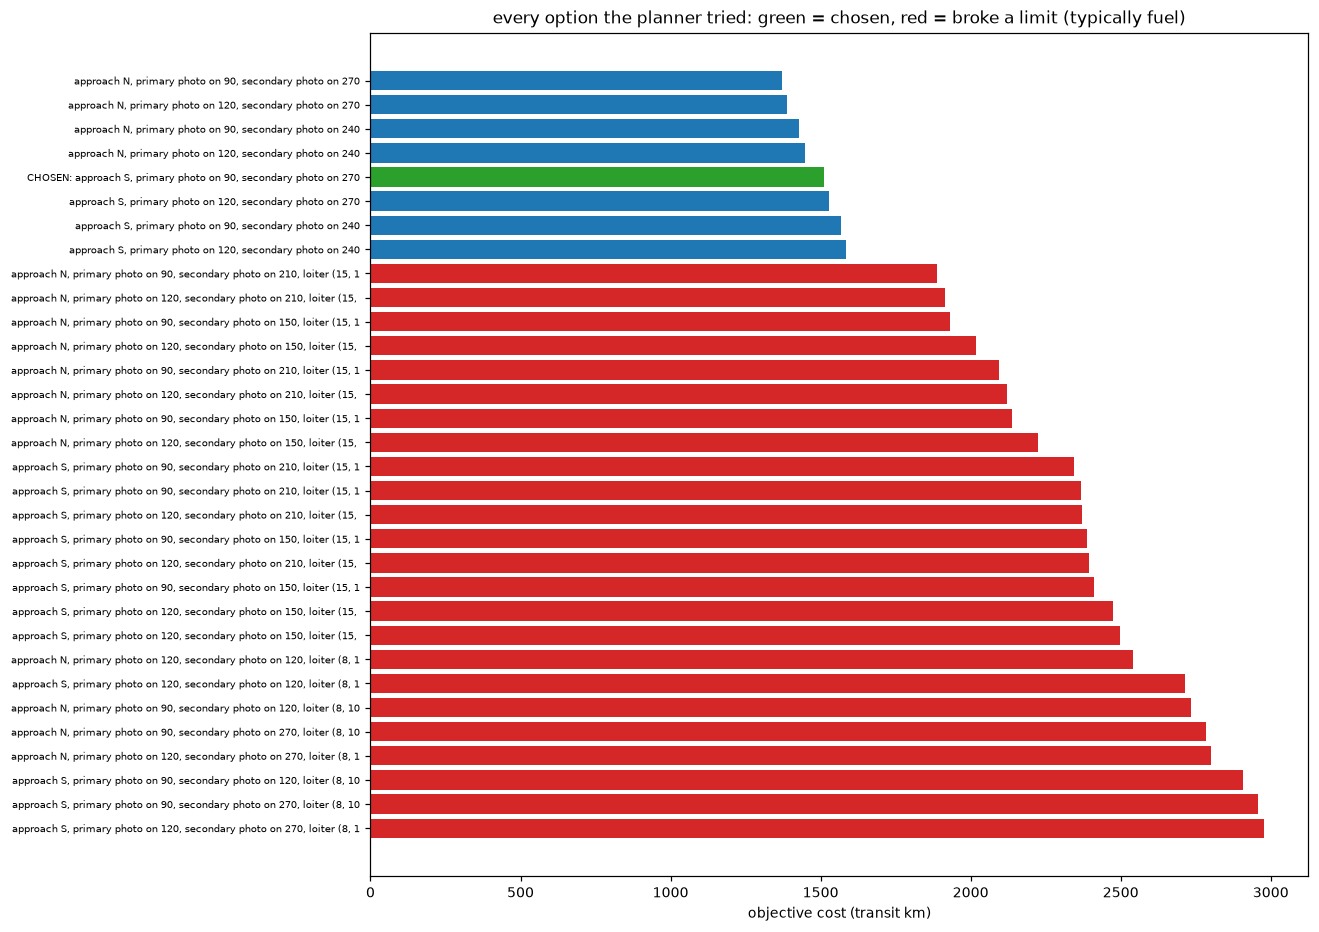

In [41]:
rep_path = D / "report.txt"
if rep_path.exists():
    txt = rep_path.read_text()
    opts = [("CHOSEN: " + m.group(1), float(stored["summary"]["cost"]), 0) for m in re.finditer(r"^CHOSEN: (.*)$", txt, re.M)]
    for m in re.finditer(r"^\s+also: (.*?): cost (\d+)(?:, (\d+) errors)?$", txt, re.M):
        opts.append((m.group(1), float(m.group(2)), int(m.group(3) or 0)))
    opts.sort(key=lambda o: (o[2] > 0, o[1]))
    fig, ax = plt.subplots(figsize=(11, 0.28 * len(opts) + 1))
    cols = ["#2ca02c" if o[0].startswith("CHOSEN") else ("#d62728" if o[2] else "#1f77b4") for o in opts]
    ax.barh(range(len(opts)), [o[1] for o in opts], color=cols)
    ax.set_yticks(range(len(opts))); ax.set_yticklabels([o[0].replace("order primary/secondary, ", "")[:70] for o in opts], fontsize=6.5)
    ax.invert_yaxis(); ax.set_xlabel("objective cost (transit km)"); ax.set_title("every option the planner tried: green = chosen, red = broke a limit (typically fuel)")
    print(len(opts), "options;", sum(1 for o in opts if o[2]), "invalid")
else:
    print("this fixture has no report.txt; run the slow cell below (or: python analysis/planner <dir>)")

### A small version you can modify

Here is a miniature of that loop: the same takeoff / targets / landing, **both approach sides × the stored attack bearings (± 30°)**,
each planned for real with `pl.plan(seq)` (~3 s each). Change `BEARINGS`, add a side, and watch the cost.

side  bearing     cost  landing lb  status
   N       60     3184          63  fuel at landing 63 lb, below the 1000 lb
   N       90     1371        3479  ok
   N      120     1388        3539  ok
   S       60     3323       -1721  fuel at landing -1721 lb, below the 1000
   S       90     1510        1694  ok
   S      120     1527        1755  ok


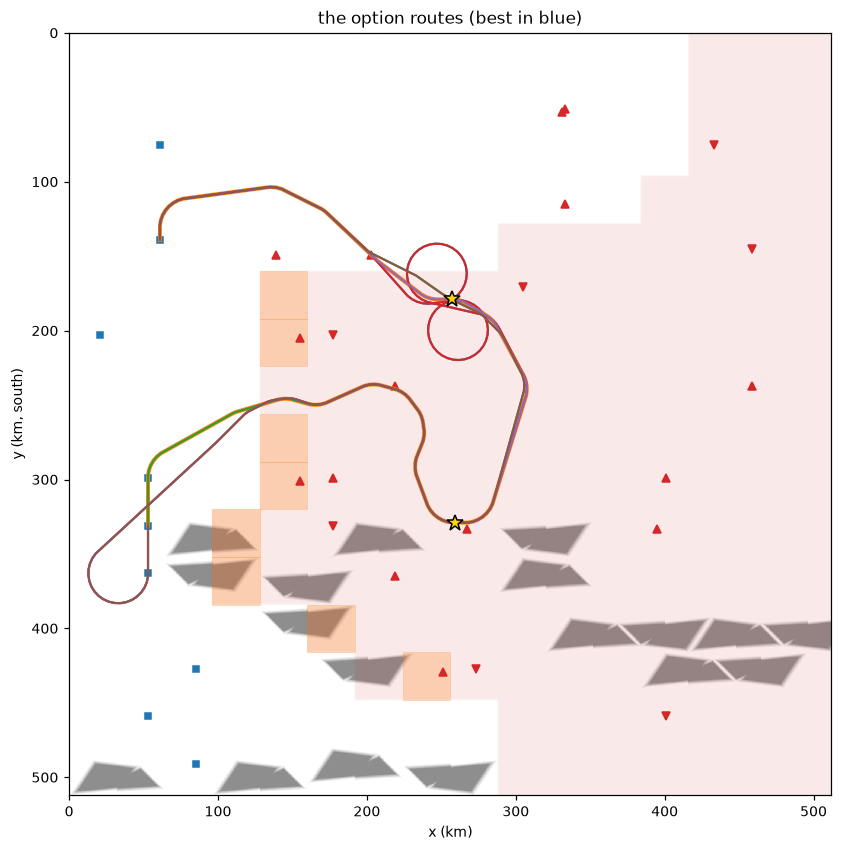

In [42]:
BEARINGS = [-30, 0, 30]            # offsets from the chosen primary bearing
base_bearing = float(re.search(r"primary (?:photo|maverick) on (\d+)", stored["chosen"]).group(1))
base_seq = chosen_sequence(pl, stored["chosen"])
rows = []
for side in ("N", "S"):
    for off in BEARINGS:
        sq = list(base_seq); sq[-1] = pl.landing(side)
        el = pl.targets(("primary",))[0]; mode_ = pl.attack_mode(tg["primary"])[0]
        idx = next(i for i, e in enumerate(sq) if e.get("role") == "primary")
        pc = pl.attack_piece(el, tg["primary"], mode_, (base_bearing + off) % 360)
        if pc is None: rows.append((side, off, None, "blocked")); continue
        sq[idx] = pc
        try: rr = pl.plan(sq); rows.append((side, off, rr, "ok" if not rr["errors"] else rr["errors"][0][:40]))
        except Exception as e: rows.append((side, off, None, str(e)[:50]))
print(f"{'side':>4s} {'bearing':>8s} {'cost':>8s} {'landing lb':>11s}  status")
for side, off, rr, st in rows:
    print(f"{side:>4s} {(base_bearing+off)%360:8.0f} " + (f"{rr['cost']:8.0f} {rr['fuel']['fuel_land']:11.0f}" if rr else f"{'-':>8s} {'-':>11s}") + f"  {st}")
fig, ax = show_map("the option routes (best in blue)", routes=[dict(pts=rr["pts"], color=f"C{i%10}", lw=1.4 if rr is not min((x[2] for x in rows if x[2]), key=lambda x: x['cost']) else 2.6)
                                                              for i, (_, _, rr, _) in enumerate(rows) if rr], labels=False)

### Loiters: farming cold-war samples where no radar can see (`loiter.py`)

With the `fuel` profile or `"loiter": "auto"` (this plan has it), the planner looks for **racetracks in enemy cells where no site can see the plane at any heading**
(mountain cells have return ×0) and, if the route has spare fuel, adds laps there: every 64 s inside an enemy cell is a sample. Building the Planner with `loiters=True` runs
the search. The first plot is the quiet mask - enemy ground where *every* site's margin is below −15 at 250 ft, loiter bank and speed:

8.1% of the map is quiet enemy ground;  3 candidate racetracks:
  cell (8, 10) SE: half-length 8 km, lap 70 km, terrain 0, peak 96 ft, 4 cells from friendly ground
  cell (15, 10) SE: half-length 14 km, lap 94 km, terrain 2, peak 96 ft, 11 cells from friendly ground
  cell (15, 11) NE: half-length 12 km, lap 86 km, terrain 2, peak 96 ft, 10 cells from friendly ground


Text(0.5, 1.0, 'quiet enemy ground (green) and the racetracks planned there (orange)')

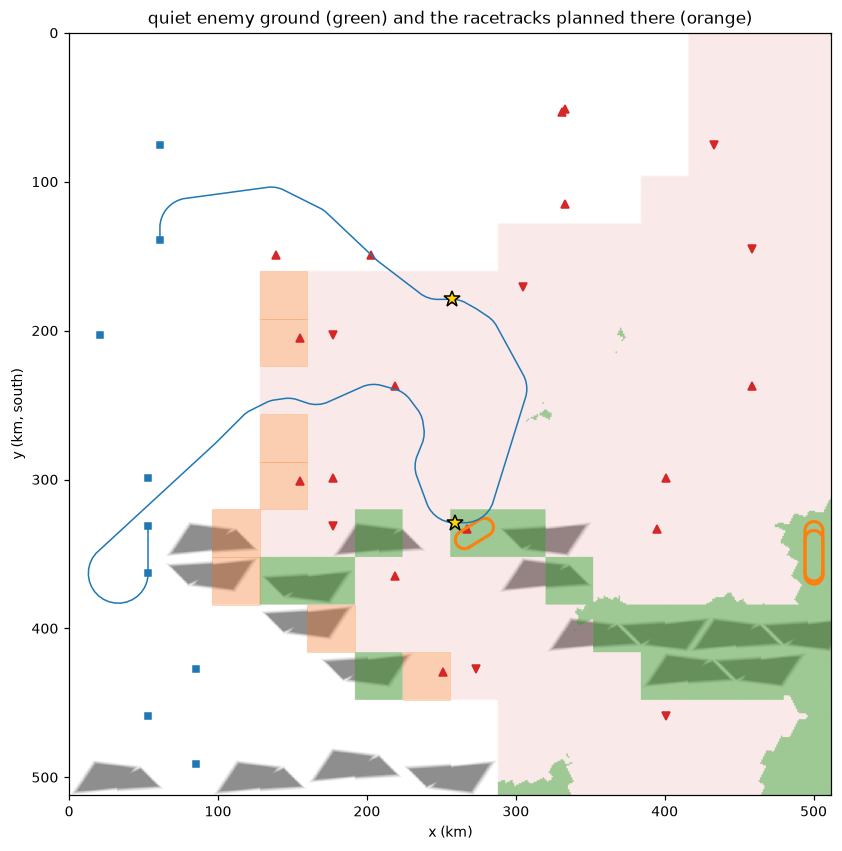

In [43]:
plL = get_planner(PLAN, loiters=True)
quiet = loiter.radar_quiet_mask(plL.W, plL.RM, plL.P)
print(f"{quiet.mean():.1%} of the map is quiet enemy ground;  {len(plL.loiters)} candidate racetracks:")
for f in plL.loiters:
    print(f"  cell {f['cell']} {f['quadrant']}: half-length {f['half_km']:.0f} km, lap {f['lap_km']:.0f} km, terrain {f['terrain']}, peak {f['peak_ft']:.0f} ft, {f['friendly_cells_away']} cells from friendly ground")
fig, ax = plt.subplots(figsize=(9, 9))
draw_world(ax, plL, labels=False)
ax.imshow(np.where(quiet, 1.0, np.nan), extent=(0, L, L, 0), cmap=ListedColormap(["#2ca02c"]), alpha=.45)
for f in plL.loiters:
    path = loiter.racetrack_path(f["centre"], f["theta"], f["half_km"], plL.P["loiter_radius_km"])
    a = xy_of(path); ax.plot(a[:, 0], a[:, 1], c="C1", lw=2)
draw_route(ax, stored["points"], color="C0", lw=1.0)
ax.set_title("quiet enemy ground (green) and the racetracks planned there (orange)")

### The whole run **(slow, ~3 min)**

Set `RUN_SLOW = True` at the top (or `RUN_FULL = True` here) to run `api.plan_mission` yourself and compare with the stored route.

In [44]:
RUN_FULL = RUN_SLOW
if RUN_FULL:
    t = time.time(); res = api.plan_mission(spec, M, str(D), progress=print); print(f"{time.time()-t:.0f} s")
    print("chosen:", res.best["tag"], "| stored:", stored["chosen"], "| same:", res.best["tag"] == stored["chosen"])
else:
    print("skipped. A recorded run of this plan took 168 s and chose the same option as the stored route.json.")

skipped. A recorded run of this plan took 168 s and chose the same option as the stored route.json.


## Step 11 · The outputs (`report.py`)

`report.summarise` computes the headline numbers (km, minutes, turns, expected seen pulses, cold-war samples, fuel, alert sim, score estimate);
`report.report` writes the text, `report.draw` the picture, `report.route_json` the file the autopilot flies. Re-create the summary from our rebuilt route and compare with the stored one:

In [45]:
best = {**r, "tag": stored["chosen"]}
summ, sim2, samples = report.summarise(pl, best)
print(f"{'':22s} {'rebuilt':>12s} {'stored':>12s}")
for k in ("km", "game_min", "turns", "exposure_pulses", "samples", "fuel_used_lb", "fuel_landing_lb", "expected_radar_ids", "cost"):
    print(f"{k:22s} {str(summ[k]):>12s} {str(stored['summary'][k]):>12s}")
print("\nscore estimate (rebuilt):", summ["score_est"], "base", summ["base_points"], "| cold-war samples in enemy cells:", summ["enemy_samples"])

                            rebuilt       stored
km                            900.9        900.9
game_min                      194.9        194.9
turns                            22           22
exposure_pulses               13.52        13.52
samples                         183          183
fuel_used_lb                  12106        12106
fuel_landing_lb                1694         1694
expected_radar_ids             0.69         0.69
cost                         1510.0       1510.0

score estimate (rebuilt): [704, 1722] base [259, 259] | cold-war samples in enemy cells: [91, 91]


Text(0.5, 1.0, 'report.draw(): route.png')

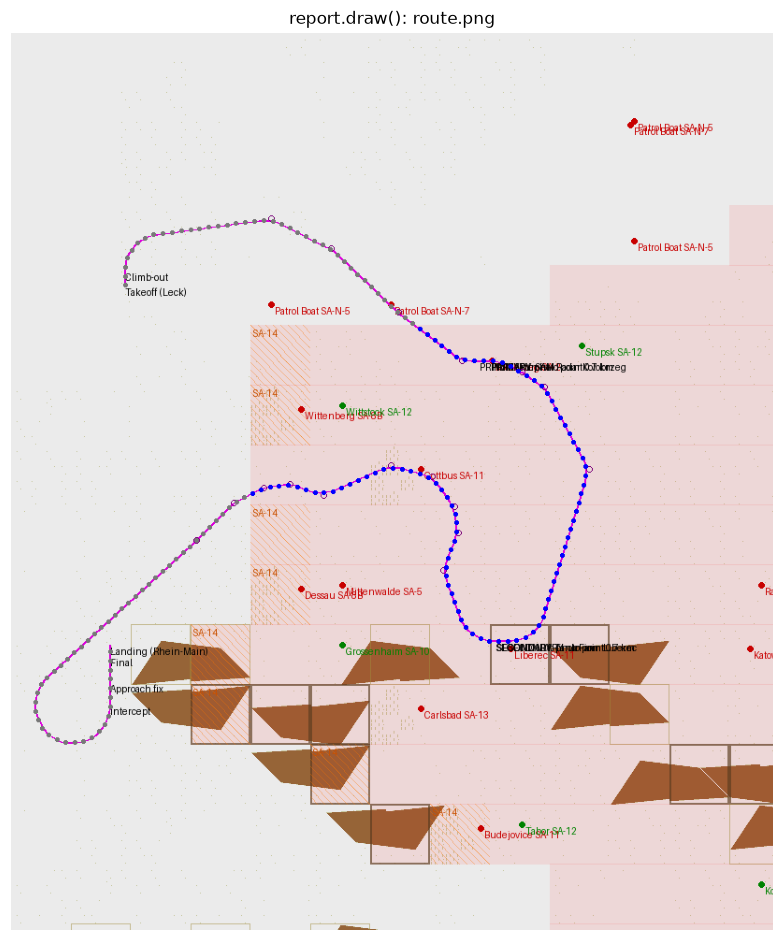

In [46]:
img = report.draw(pl, best, samples)
plt.figure(figsize=(9, 9 * img.size[1] / img.size[0])); plt.imshow(img); plt.axis("off"); plt.title("report.draw(): route.png")

In [47]:
route_json = report._route_json = report.route_json(pl, best, spec, summ)
pts = route_json["points"]
print("route.json keys:", list(route_json))
print(f"{len(pts)} points; the autopilot flies these. First rows:")
for p in pts[:3] + pts[-3:]: print({k: (round(v, 1) if isinstance(v, float) else v) for k, v in p.items()})
print("\nreport.txt, head:")
print((D / "report.txt").read_text()[:1500] if (D / "report.txt").exists() else "(no stored report for this fixture)")

route.json keys: ['schema', 'spec', 'profile', 'summary', 'chosen', 'errors', 'takeoff_heading', 'waypoints_game', 'points']
149 points; the autopilot flies these. First rows:
{'x': 3904.0, 'y': 8896.0, 'label': 'Takeoff (Leck)', 'kind': 'takeoff', 'throttle': 50, 'flaps': True, 'speed_kt': 190, 'fuel_lb': 10000, 't_game_s': 0}
{'x': 3904.0, 'y': 8384.0, 'label': 'Climb-out', 'kind': 'climb', 'throttle': 50, 'flaps': True, 'speed_kt': 190, 'fuel_lb': 9892, 't_game_s': 104}
{'x': 3904.0, 'y': 8268.7, 'label': '', 'throttle': 50, 'flaps': True, 'speed_kt': 190, 'fuel_lb': 9868, 't_game_s': 127, 'alt_ft': 700}
{'x': 3392.0, 'y': 22464.0, 'label': 'Approach fix', 'kind': 'approach', 'throttle': 50, 'flaps': True, 'speed_kt': 190, 'fuel_lb': 1963, 't_game_s': 11437}
{'x': 3392.0, 'y': 21568.0, 'label': 'Final', 'kind': 'final', 'throttle': 50, 'flaps': True, 'speed_kt': 190, 'fuel_lb': 1775, 't_game_s': 11619}
{'x': 3392.0, 'y': 21184.0, 'label': 'Landing (Rhein-Main)', 'kind': 'landing', '

## Step 12 · In flight: `route(pose, goals)` (`api.py`)

Once the plane is flying, replanning must take seconds, not minutes. `api.context(spec, mission)` builds the expensive objects once (World, radar model, price grids; no loiter search),
and `api.route(state, goals, constraints, budget_s, planner=ctx)` plans from the **current pose** (position, heading, fuel, clock, tanks left) to a goal or chain of goals:

* `Goal.point(x, y)` · `Goal.target(role, mode, bearing)` · `Goal.landing(base, side)` · `Goal.rejoin(points, index)` (splice back onto the reference route).

It plans **one** option (no order / side / bearing / loiter product), in a bounded search box, with a time budget, re-integrating fuel from the pose. The start piece flies the current heading `lead_km` before the first turn.
Below: take the stored route, put the plane 35 % of the way along it and **fly off the route 30 km** (as if it had been pushed off by a reaction), then ask for a route that rejoins.

pose: Pose(x=np.float64(17812.233753096556), y=np.float64(15017.695827164349), heading=197.25096206749132, alt_ft=250, fuel_lb=5579, t=4272, tanks=2)


1.1 s; feasible=True; errors=[]; violations=[]; fuel at end 1562 lb


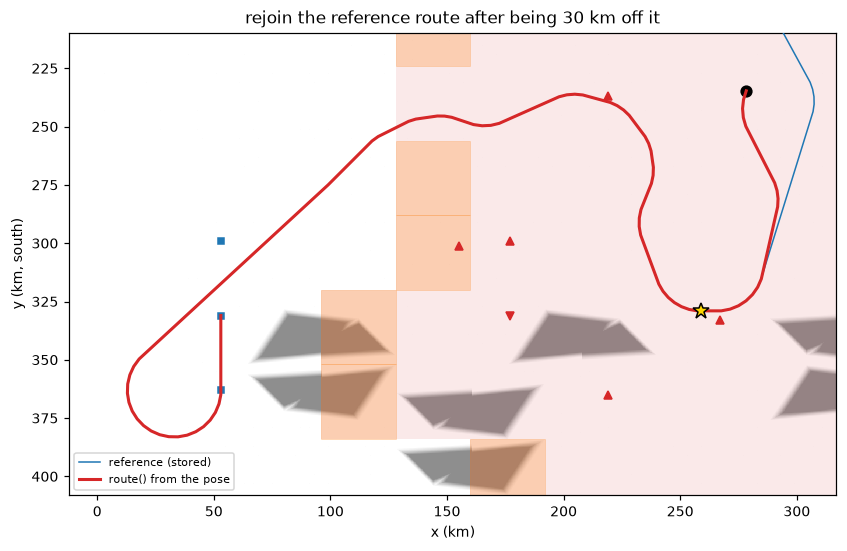

In [48]:
ctx = api.context(spec, M)
ref = stored["points"]
i0 = int(len(ref) * 0.35)
p0, p1 = ref[i0], ref[i0 + 1]
h = hdg((p1["x"] - p0["x"], p1["y"] - p0["y"]))
off = from_hdg(h + 90) * 30 * K
pose = api.Pose(x=p0["x"] + off[0], y=p0["y"] + off[1], heading=h, alt_ft=p0.get("alt_ft", 700), fuel_lb=p0["fuel_lb"], t=p0["t_game_s"], tanks=2)
print("pose:", pose)
t = time.time()
rr = api.route(pose, api.Goal.rejoin(ref), (FuelConstraint(),), budget_s=20, planner=ctx)
print(f"{time.time()-t:.1f} s; feasible={rr.feasible}; errors={rr.errors}; violations={rr.violations}; fuel at end {rr.fuel_end_lb:.0f} lb")
bx = bbox_of(rr.pts, 25)
fig, ax = show_map("rejoin the reference route after being 30 km off it", routes=[
    dict(pts=ref, color="C0", lw=1.0, label="reference (stored)"), dict(pts=rr.pts, color="C3", lw=2, label="route() from the pose")],
    crop=bx, labels=False)
ax.plot(pose.x / K, pose.y / K, "ko", ms=7)

Goals chain. Fly from the same pose to the **secondary target** and then land, picking the attack bearing the planner would (`bearing=None` = straight in from where the route comes from; if that fails
a ladder of variants is tried before the error is raised, `_variants`):

3.4 s; feasible=True; lands=True; 102 points; fuel at landing 2318 lb; violations=[]


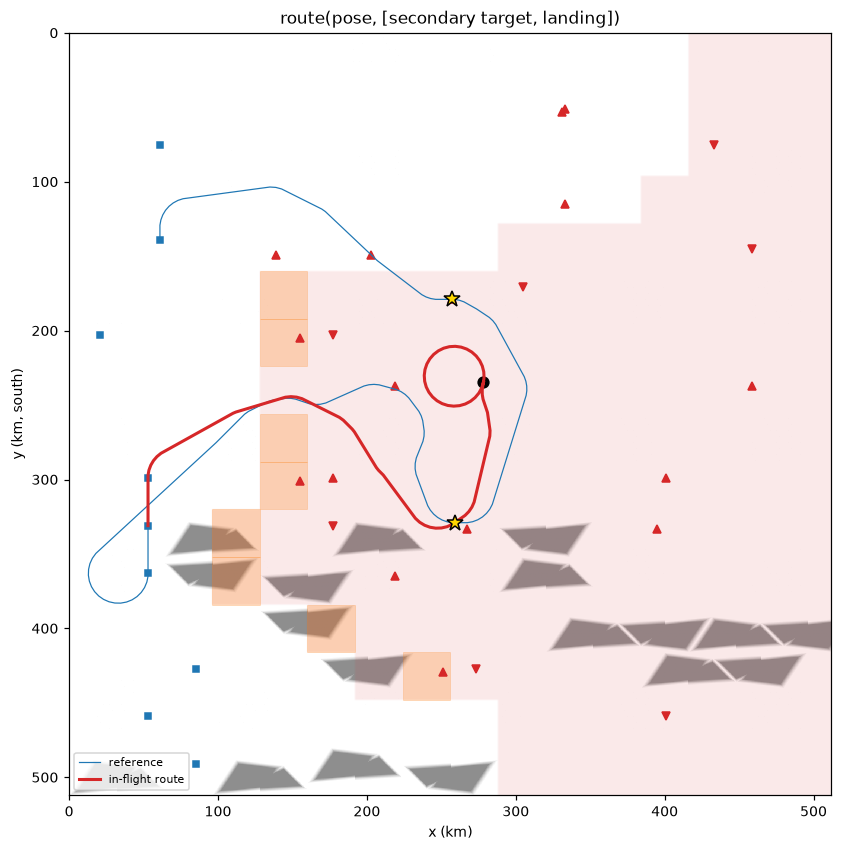

In [49]:
t = time.time()
try:
    r2 = api.route(pose, [api.Goal.target("secondary"), api.Goal.landing()], (FuelConstraint(),), budget_s=40, planner=ctx)
    print(f"{time.time()-t:.1f} s; feasible={r2.feasible}; lands={r2.lands}; {len(r2.pts)} points; fuel at landing {r2.fuel_end_lb:.0f} lb; violations={r2.violations}")
    fig, ax = show_map("route(pose, [secondary target, landing])", routes=[dict(pts=ref, color="C0", lw=.8, label="reference"), dict(pts=r2.pts, color="C3", lw=2, label="in-flight route")], labels=False)
    ax.plot(pose.x / K, pose.y / K, "ko", ms=7)
except Exception as e:
    print(f"{time.time()-t:.1f} s; {type(e).__name__}: {e}")

## Experiments: change the inputs and watch the plan move

Each cell builds a fresh `Planner` (a second or two: World + radar model + price grids) and plans the *same* sequence, so only the knob you turned changes.
The attack pieces and landing side come from the stored plan.

### Profile presets on one mission

`stealth` pays 10 samples per seen pulse; `fast` pays 0.5 and flies 70 % throttle; `balanced` 3. How much do you trade?

profile        km    min  turns  seen pulses  lb@land  P(launch)   IDs errors
stealth       901    195     22         13.5     1694        35%  0.69 []
balanced      859    186     18         13.6     2257        90%  1.33 []
fast          831    180     16         29.0     2632        98%  1.88 []


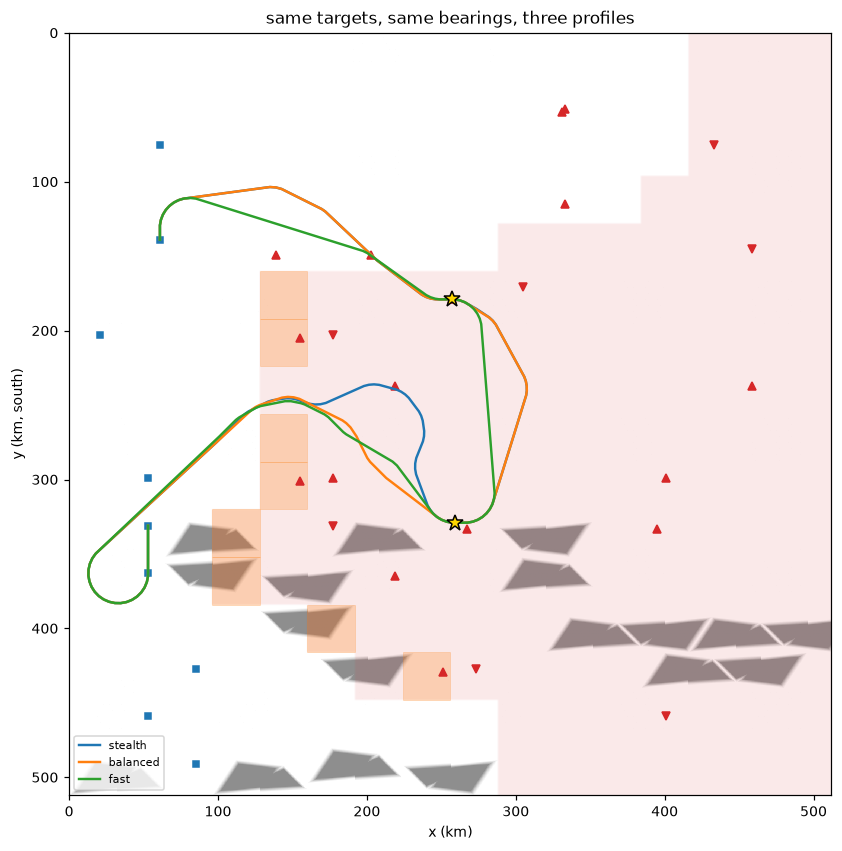

In [50]:
def plan_with(name=PLAN, **spec_over):
    p = get_planner(name, **spec_over)
    D_, sp, M_, st = load_plan(name)
    sq = chosen_sequence(p, st["chosen"])
    t0 = time.time(); rr = p.plan(sq); dt = time.time() - t0
    s, _, _ = report.summarise(p, {**rr, "tag": "x"})
    return p, rr, s, dt

results = {}
for prof in ("stealth", "balanced", "fast"):
    try: results[prof] = plan_with(profile=prof)
    except Exception as e: print(prof, "failed:", e)
print(f"{'profile':10s} {'km':>6s} {'min':>6s} {'turns':>6s} {'seen pulses':>12s} {'lb@land':>8s} {'P(launch)':>10s} {'IDs':>5s} {'errors'}")
for prof, (p, rr, s, dt) in results.items():
    e = s["alert"]["expected"]
    print(f"{prof:10s} {s['km']:6.0f} {s['game_min']:6.0f} {s['turns']:6d} {s['exposure_pulses']:12.1f} {s['fuel_landing_lb']:8d} {e['p_any_launch']:10.0%} {e['expected_ids']:5.2f} {rr['errors'][:1]}")
fig, ax = show_map("same targets, same bearings, three profiles", routes=[dict(pts=rr["pts"], color=f"C{i}", lw=1.6, label=prof) for i, (prof, (_, rr, _, _)) in enumerate(results.items())], labels=False)

### Opponent level

The opponent level scales every site's return and moves the SA-14 / altitude rules (`low_in_enemy_from_opp`, `sa14_hard_from_opp`). Same mission planned for each level:

In [51]:
res_opp = {}
for opp in ("green", "veteran", "elite"):
    try: res_opp[opp] = plan_with(settings={**spec["settings"], "opponent": opp})
    except Exception as e: print(opp, "failed:", e)
print(f"{'opponent':9s} {'km':>6s} {'seen pulses':>12s} {'lb@land':>8s} {'P(launch)':>10s} {'IDs':>5s}")
for opp, (p, rr, s, dt) in res_opp.items():
    e = s["alert"]["expected"]
    print(f"{opp:9s} {s['km']:6.0f} {s['exposure_pulses']:12.1f} {s['fuel_landing_lb']:8d} {e['p_any_launch']:10.0%} {e['expected_ids']:5.2f}   {rr['errors'][:1]}")

opponent      km  seen pulses  lb@land  P(launch)   IDs
green        828          0.0     2674         0%  0.00   []
veteran      832          1.8     2618         0%  0.00   []
elite        901         13.5     1694        35%  0.69   []


### SA-14 cells

By day, live SA-14 cells (territory bit 4) are a price below Elite and **walls at Elite** (`sa14_hard`); at night they are harmless (`World.sa14_cells` is masked by `night`). `settings.sa14` = `auto` / `hard` / `soft` overrides the rule. Which fixtures have them:

In [52]:
for name in ["ce_kolobrzeg_1022_2250", "ce_liberec_1027_0916", "pg_shiraz_1024_1514", "ce_budejovice_1023_1811"]:
    D_, sp, M_, st = load_plan(name)
    p = get_planner(name)
    print(f"{name:28s} live SA-14 cells by day: {int(p.W.sa14_cells.sum()):2d}  hard={p.W.sa14_hard}  stored sa14 minutes: {st['summary']['sa14_minutes']}")

ce_kolobrzeg_1022_2250       live SA-14 cells by day:  8  hard=True  stored sa14 minutes: 0.0


ce_liberec_1027_0916         live SA-14 cells by day:  8  hard=False  stored sa14 minutes: 4.9


pg_shiraz_1024_1514          live SA-14 cells by day: 16  hard=True  stored sa14 minutes: 4.5


ce_budejovice_1023_1811      live SA-14 cells by day:  8  hard=True  stored sa14 minutes: 7.8


### The other plans, rebuilt and compared with what was stored

If the planner is deterministic (it is), rebuilding the stored choice must give the stored cost. This is also a handy regression check when you change the planner:

In [53]:
print(f"{'plan':28s} {'cost':>8s} {'stored':>8s} {'km':>6s} {'stored':>7s} {'lb@land':>8s} {'stored':>7s} {'same?':>6s}")
for name in sorted(p.name for p in FIXTURES.iterdir()):
    try:
        pp, rr, s, dt = plan_with(name)
        st = load_plan(name)[3]["summary"]
        same = abs(rr["cost"] - st["cost"]) < 1.0
        print(f"{name:28s} {rr['cost']:8.0f} {st['cost']:8.0f} {s['km']:6.0f} {st['km']:7.0f} {s['fuel_landing_lb']:8d} {st['fuel_landing_lb']:7d} {str(same):>6s}")
    except Exception as e:
        print(f"{name:28s} could not rebuild: {type(e).__name__}: {str(e)[:90]}")
print("\nA plan that cannot be rebuilt was stored by an older planner than the code in this checkout (e.g. before the SA-14 wall rule,"
      " which rejects attack pieces and paths through live SA-14 cells at Elite). That is what this table is for.")

plan                             cost   stored     km  stored  lb@land  stored  same?
ce_budejovice_1023_1811      could not rebuild: TypeError: 'NoneType' object is not subscriptable


ce_kolobrzeg_1022_2250           1510     1510    901     901     1694    1694   True


ce_liberec_1027_0916             2424     2424    946     946     1084    1084   True


pg_shiraz_1024_1514          could not rebuild: PlanError: no path from (11072,23616) to (17402,10617) arriving on heading 150 with the SA-14 cells w

A plan that cannot be rebuilt was stored by an older planner than the code in this checkout (e.g. before the SA-14 wall rule, which rejects attack pieces and paths through live SA-14 cells at Elite). That is what this table is for.


## Beyond fuel: optimising for career points (a Lagrangian exercise)

Everything above prices things in **transit km**, a proxy for fuel. But fuel is only an *input* to what we care about: career points, and staying alive to earn more of them.
This section builds a planner objective on points directly, using (a) the decoded scoring rules, (b) the decoded damage rules, and (c) counts from the logged flights.

### What the score contains (`docs/game/scoring-awards.md`, `f19.rules.scoring`)

```
score = M × ( enemy_samples + 140 [primary] + 35 [secondary, with primary] − 10 × radar_IDs − 20 × visual_IDs )
M     = theater × mission × opponent × landing × fuel_estimate_bucket / 8⁵          (fixed by the menus + briefing, NOT by the route)
eject: score × [2,3,6,4][side of the cell you are over] / 8   (enemy cell = 2/8, confirmed; the others unverified)
crash or safe landing: no score change.  Running score is clamped at ≥ 0, so an early shoot-down is simply a ~0-point outcome.
```

* **Being detected costs nothing by itself**; only IDs do. Detection matters through the chain *alert → launch → hit → damage*.
* **Burning fuel costs nothing; running out does.** Fuel matters as samples you can still farm and as protection against flame-out.

### The decisions this section builds on

1. **P(die | eject) = 0, *provided* the aircraft is level when it ejects.** The decoded roll (`docs/game/landing-takeoff.md`, 2026-10-28) is `S = |pitch|/32 + |roll|/32 + kt` against `500 + rand(300)`;
   it does not depend on altitude, so a level-flight check before ejecting makes it 0. That check is a requirement on the ejection sequence, tracked as the knob `p_unlevel` below (default 0).
2. **Damage that matters is the bay doors and the fuel tank.** A hit sets `opp + 1` random damage bits. Bay doors jammed open (bit `0x10`) add +24 EMV for the rest of the flight, so we treat that as *bail out*. A leak (`0x20`) burns `count` extra lb per 4 s. Other systems are ignored.
3. **λ (what staying alive is worth) is a constant, 30,000 points.** It is only a risk threshold: with ejection safe, the only death risk left is ejecting un-level, so λ prices `p_unlevel`.
4. **Early shoot-downs are not penalised separately.** The points accrued when the hit comes are simply lower, and the score cannot go below 0.

**Difficulty.** Everything counted below is labelled with the level it was counted at. Veteran is our default and Elite the stretch goal, and the damage rules scale with the level (`opp + 1` bits per hit). The logs hold 21 Veteran flights
(58 SA-14 launches and no hit, no fighter launch) and 7 Elite flights (all the hits). The Kolobrzeg plan used here is an **Elite** plan, so the Elite numbers are the relevant ones for it; the Veteran column applies the Veteran hazard to the same routes only to show the contrast (the radar planning would differ).

The chain is then
```
E[points] = Σ over hits in time:  P(bay hit at t) · points_if_ejected_at(t)  +  P(leak hit at t) · points_if_truncated_at(t)  +  P(no damage) · points_if_landed
```
with every probability either **decoded exactly from the game** or **counted from the flight logs**, below.

### What is decoded and what is counted

| quantity | source | value |
|---|---|---|
| P(bay jammed \| one hit), P(leak \| one hit) | **decoded** (hit routine 0x7A0B: `opp+1` draws of `1 << random(8)`) | `1 − (7/8)^(opp+1)`: **33 %** Veteran, **41 %** Elite |
| extra fuel burn after a leak | **decoded** (0x26A4: `+count` lb per 4 s; `count = 2 + (opp+1) × hits`) | `15 × count` lb/min |
| P(launch \| launch possible) | **counted**, next cells | |
| P(hit \| launch), by launcher type | **counted** | |
| how often fighters launch | **counted** | |

The next cell reads every logged flight (cached after the first run) and extracts, per flight: opponent level, minutes airborne and over enemy ground, every enemy missile flight with its launcher type and outcome
(a hit is the damage count rising by `opp + 1` right after the missile's last sighting, as `analysis/missile_game.py` defines it), and every "launch possible" episode of the radar sites.

In [54]:
import sys, glob, collections, itertools, random
from math import erf, sqrt
from dataclasses import dataclass, replace
from f19.rules import scoring
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "missile_game.py").exists())
sys.path.insert(0, str(ROOT / "analysis"))
from f19.rules import radar as rg

CACHE = S.logs / "analysis" / "missile_exposure.json"
REFRESH = False                                    # True: re-read every memlog (a few minutes)

def mine_runs():
    import missile_game as mg
    out = []
    for run in sorted(Path(p).name for p in glob.glob(str(S.logs / "memlog/*"))):
        snaps = mg.load_run(run)                  # [] for runs whose memory layout isn't readable (older flights)
        if len(snaps) < 50: continue
        opp = snaps[0]["world"]["opp"]
        t_air = t_en = 0.0
        for a, b in zip(snaps, snaps[1:]):
            dt = (b["clock"] - a["clock"]) % 65536 * 2.0
            p = a["player"]
            if not 0 < dt <= 120 or p["alt"] <= 100 or p["kt"] < 80: continue
            t_air += dt
            if a["grid"][min(p["y"] >> 11, 15) * 16 + min(p["x"] >> 11, 15)] & 3 == 0: t_en += dt
        tracks = []
        for sp, lau, tr in mg.tracks(snaps):
            (k0, m0), (kl, _) = tr[0], tr[-1]
            if kl + 1 >= len(snaps): continue
            a, b = snaps[k0], snaps[kl]
            tracks.append(dict(name=m0.name, rec=lau, k0=k0, cls="fighter" if lau < 0 else "SA-14" if lau == 1 else "site",
                               hit=snaps[kl + 1]["dmg"] - snaps[kl]["dmg"] == opp + 1, seen_s=(b["clock"] - a["clock"]) % 65536 * 2.0,
                               cm_used=sum(max(0, x - y) for x, y in zip(a["stores"], b["stores"])), stores=list(a["stores"])))
        episodes, last = [], {}
        for k, s in enumerate(snaps):                       # a site is in "launch possible" while alert > 0xC0 and the plane is inside its SAM range
            p = s["player"]
            for r, site in s["sites"].items():
                if site["dead"] or site["alert"] <= 0xC0: continue
                try: rng_km = rg.sam_range_km(site["type"])
                except Exception: continue
                if rng_km and rg.game_dist(int(p["x"] - site["x"]), int(p["y"] - site["y"])) >> 6 <= rng_km:
                    if last.get(r) != k - 1: episodes.append([r, k, k])
                    else: episodes[-1 if episodes[-1][0] == r else max(i for i, e in enumerate(episodes) if e[0] == r)][2] = k
                    last[r] = k
        for e in episodes: e.append(any(t["cls"] == "site" and t["rec"] == e[0] and e[1] - 3 <= t["k0"] <= e[2] + 3 for t in tracks))
        first_hits = [(snaps[k]["world"]["dmg_bits"], snaps[k + 1]["world"]["dmg_bits"]) for k in range(len(snaps) - 1) if snaps[k + 1]["dmg"] > snaps[k]["dmg"]]
        out.append(dict(run=run, opp=opp, air_min=t_air / 60, enemy_min=t_en / 60, tracks=tracks, episodes=episodes, hit_bits=first_hits))
    return out

if CACHE.exists() and not REFRESH: runs_data = json.load(open(CACHE))
else:
    t0 = time.time(); runs_data = mine_runs(); CACHE.parent.mkdir(parents=True, exist_ok=True); json.dump(runs_data, open(CACHE, "w"))
    print(f"mined in {time.time()-t0:.0f} s")
print(f"{len(runs_data)} readable flights: " + ", ".join(f"{n} {sum(1 for r in runs_data if r['opp'] == o)}" for o, n in enumerate(("Green", "Regular", "Veteran", "Elite"))))

33 readable flights: Green 4, Regular 1, Veteran 21, Elite 7


### P(launch | launch possible)

For a radar site, "launch possible" means alert > 0xC0 with the plane inside the site's SAM range (what `alertsim` flags). Each such episode in the logs, and whether a missile from that site actually followed:

In [55]:
ep = [(r["opp"], e) for r in runs_data for e in r["episodes"]]
n_ep = len(ep); n_launched = sum(1 for _, e in ep if e[3])
print(f"launch-possible episodes in the logs: {n_ep}; followed by a launch from that site: {n_launched}")
for o in (2, 3):
    E_ = [e for oo, e in ep if oo == o]; print(f"  {('Veteran','Elite')[o-2]}: {len(E_)} episodes, {sum(1 for e in E_ if e[3])} with a launch")
n_site_launch = sum(1 for r in runs_data for t in r["tracks"] if t["cls"] == "site")
print(f"site launches overall: {n_site_launch}  ->  {n_site_launch / max(n_ep, 1):.1f} launches per episode")
print(f"\n=> P(launch | launch possible) = {n_launched}/{n_ep} here (Elite only: Veteran had no site episode in 21 flights), and a launched site fires {n_site_launch / max(n_launched, 1):.1f} missiles per episode. "
      "Close enough to 1 that the alert sim's 'launch possible' can be read as 'a launch'; the one without a launch is probably a gate (slot busy, or a missile already homing).")

launch-possible episodes in the logs: 6; followed by a launch from that site: 5
  Veteran: 0 episodes, 0 with a launch
  Elite: 6 episodes, 5 with a launch
site launches overall: 11  ->  1.8 launches per episode

=> P(launch | launch possible) = 5/6 here (Elite only: Veteran had no site episode in 21 flights), and a launched site fires 2.2 missiles per episode. Close enough to 1 that the alert sim's 'launch possible' can be read as 'a launch'; the one without a launch is probably a gate (slot busy, or a missile already homing).


### P(hit | launch), and who is hitting us

Every enemy missile flight in the logs, by launcher type: ground SAM sites, SA-14 cells, and **fighters** (launcher index < 0). Intervals are Wilson 90 %; remember that flights cluster in a few runs.

In [56]:
def wilson(k, n, z=1.645):
    if n == 0: return (0.0, 1.0)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

print(f"{'opponent':9s} {'launcher':8s} {'launches':>8s} {'hits':>5s} {'P(hit|launch)':>14s} {'90% interval':>15s}  {'runs with launches':>18s}")
for o, name in ((2, "Veteran"), (3, "Elite")):
    for cls in ("site", "SA-14", "fighter"):
        T_ = [(r["run"], t) for r in runs_data if r["opp"] == o for t in r["tracks"] if t["cls"] == cls]
        if not T_: print(f"{name:9s} {cls:8s} {0:8d}"); continue
        n_, k_ = len(T_), sum(t["hit"] for _, t in T_); lo, hi = wilson(k_, n_)
        print(f"{name:9s} {cls:8s} {n_:8d} {k_:5d} {k_/n_:14.0%} {f'{lo:.0%} - {hi:.0%}':>15s}  {len({r for r, _ in T_}):18d}")
n_other = sum(1 for r in runs_data for t in r["tracks"] if t["cls"] != "fighter"); h_other = sum(1 for r in runs_data for t in r["tracks"] if t["cls"] != "fighter" and t["hit"])
print(f"\nEvery hit in the logs is a fighter missile at Elite. Ground SAMs and SA-14s have hit {h_other} times in {n_other} launches.")

opponent  launcher launches  hits  P(hit|launch)    90% interval  runs with launches
Veteran   site            0
Veteran   SA-14          58     0             0%         0% - 4%                   6
Veteran   fighter         0
Elite     site           11     0             0%        0% - 20%                   3
Elite     SA-14           2     0             0%        0% - 58%                   1
Elite     fighter        23    10            43%       28% - 60%                   4

Every hit in the logs is a fighter missile at Elite. Ground SAMs and SA-14s have hit 0 times in 71 launches.


**This matters for the planner.** `alertsim` models radar sites and SA-14 cells; its own docstring says aircraft radars are *not modelled*. But all the damage we have ever taken came from fighters. The route's modelled launch probability is therefore a poor proxy for the risk that
actually costs points. Why the sites are harmless in practice, and whether the fighter hits were evadable:

In [57]:
print("warning time = seconds between the first and last snapshot a missile was visible; stores = (flares, chaff, decoys) at first sight")
for o, cls in ((3, "fighter"), (3, "site")):
    T_ = [t for r in runs_data if r["opp"] == o for t in r["tracks"] if t["cls"] == cls]
    hits = [t for t in T_ if t["hit"]]; miss = [t for t in T_ if not t["hit"]]
    f = lambda L: f"median {np.median([t['seen_s'] for t in L]):.0f} s (range {min(t['seen_s'] for t in L):.0f}-{max(t['seen_s'] for t in L):.0f})" if L else "-"
    print(f"Elite {cls:8s}: hits {len(hits):2d}, warning {f(hits)}; non-hits {len(miss):2d}, warning {f(miss)}")
    print(f"               countermeasure used: on {sum(t['cm_used'] > 0 for t in hits)}/{len(hits)} of the hits, {sum(t['cm_used'] > 0 for t in miss)}/{len(miss)} of the non-hits")
H_ = [t for r in runs_data if r["opp"] == 3 for t in r["tracks"] if t["cls"] == "fighter" and t["hit"]]
# which store beats which missile (docs/game/missiles-countermeasures.md section 3): AA-8 IR tail -> flare; AA-9 semi-active radar -> chaff; AA-10 all-aspect radar -> decoy (chaff only on the beam); a decoy beats everything
BEATS = {"AA-8": (0,), "AA-9": (1, 2), "AA-10": (2,)}                     # indices into stores (flares, chaff, decoys); decoy (2) is always allowed
def evadable(t): return t["seen_s"] >= 4 and any(t["stores"][i] > 0 for i in set(BEATS.get(t["name"], ())) | {2})
print(f"\nElite fighter hits: {len(H_)}.  warning >= 4 s: {sum(t['seen_s'] >= 4 for t in H_)}.  of those, a store that beats that missile was in stock: {sum(evadable(t) for t in H_)}.")
print("by missile:", dict(collections.Counter(t["name"] for t in H_)), "| decoys left at first sight on the hits:", [t["stores"][2] for t in H_])
print("(the one flight with six hits had spent all three decoys on slow SAM shots earlier: 0 of 3 left when the fighters came)")

warning time = seconds between the first and last snapshot a missile was visible; stores = (flares, chaff, decoys) at first sight
Elite fighter : hits 10, warning median 5 s (range 0-12); non-hits 13, warning median 4 s (range 0-54)
               countermeasure used: on 0/10 of the hits, 0/13 of the non-hits
Elite site    : hits  0, warning -; non-hits 11, warning median 58 s (range 0-160)
               countermeasure used: on 0/0 of the hits, 7/11 of the non-hits

Elite fighter hits: 10.  warning >= 4 s: 7.  of those, a store that beats that missile was in stock: 3.
by missile: {'AA-9': 6, 'AA-10': 4} | decoys left at first sight on the hits: [3, 3, 3, 3, 0, 0, 0, 0, 0, 0]
(the one flight with six hits had spent all three decoys on slow SAM shots earlier: 0 of 3 left when the fighters came)


Reading it: ground SAMs give 46-160 s of warning, mostly get countermeasures, and never hit. Fighter missiles are visible for ~5 s (often only the last snapshot) and **no countermeasure was used on any of the 23**.
So "evadable" is a property of the *reaction*, not the geometry. In principle a fighter shot with at least ~4 s of warning and a store that beats it (decoys stop all missile damage for 48 s at Elite; chaff beats the semi-active AA-9; flares beat the IR AA-8) can be evaded, and the cell above counts how many of the 10 hits were that.
One of the hit flights spent its decoys on slow SAM shots first, which is a countermeasure *policy* point: the SAMs (46-160 s of warning, 0 hits in 71) are the ones that did not need them.
For the planner the useful number is the *current* hit rate with the present reactions, 43 % of Elite fighter launches; it should fall as reactions are added, so it is a parameter, not a constant. The warning times above are lower bounds (snapshots are about 2.6 game s apart).

### How often do fighters shoot? A hazard per airborne minute

Launches cluster in a few flights (a fighter that has the plane tends to fire repeatedly), so the honest estimate is a rate per airborne minute with a bootstrap over *flights*:

In [58]:
def hazard(o, cls="fighter", what="hit", boots=4000, seed=1):
    R = [r for r in runs_data if r["opp"] == o]
    mins = np.array([r["air_min"] for r in R]); k = np.array([sum(1 for t in r["tracks"] if t["cls"] == cls and (t["hit"] or what == "launch")) for r in R], float)
    rate = k.sum() / mins.sum() if mins.sum() else 0.0
    rng = np.random.default_rng(seed); ix = rng.integers(0, len(R), (boots, len(R)))
    bs = np.array([k[i].sum() / mins[i].sum() for i in ix])
    return rate, np.percentile(bs, 5), np.percentile(bs, 95), mins.sum(), int(k.sum()), len(R)

print(f"{'opponent':9s} {'event':14s} {'airborne min':>12s} {'flights':>7s} {'count':>6s} {'per min':>9s} {'90% (resample flights)':>24s}")
for o, name in ((2, "Veteran"), (3, "Elite")):
    for what in ("launch", "hit"):
        rate, lo, hi, m_, k_, n_ = hazard(o, "fighter", what)
        print(f"{name:9s} fighter {what:6s} {m_:12.0f} {n_:7d} {k_:6d} {rate:9.4f} {f'{lo:.4f} - {hi:.4f}':>24s}")
rate_v = hazard(2, "fighter", "hit")
print(f"\nVeteran: no fighter launch in {rate_v[3]:.0f} airborne minutes. Rule of three: the true rate is probably below {3 / rate_v[3]:.4f} per minute (95 %).")
print("Elite: only 7 flights, and they are short because they ended at the first serious damage, so hits per minute of exposure is biased high; treat it as an upper-ish planning value. Veteran: 21 flights, zero.")

opponent  event          airborne min flights  count   per min   90% (resample flights)
Veteran   fighter launch         1878      21      0    0.0000          0.0000 - 0.0000
Veteran   fighter hit            1878      21      0    0.0000          0.0000 - 0.0000
Elite     fighter launch          347       7     23    0.0662          0.0079 - 0.1873
Elite     fighter hit             347       7     10    0.0288          0.0040 - 0.0753

Veteran: no fighter launch in 1878 airborne minutes. Rule of three: the true rate is probably below 0.0016 per minute (95 %).
Elite: only 7 flights, and they are short because they ended at the first serious damage, so hits per minute of exposure is biased high; treat it as an upper-ish planning value. Veteran: 21 flights, zero.


### Damage: which system does a hit break? (decoded, exact)

A hit runs `repeat opp+1 times: bits |= 1 << random(8)`. Bay doors are bit 4, the fuel leak bit 5, so each draw hits each with probability 1/8. Closed forms for `n = opp + 1` draws, checked against a simulation of the rule and against the first hits in the logs:

In [59]:
def dmg_probs(n):
    """P(bay), P(leak), P(both), P(neither) after one hit of n draws."""
    return dict(bay=1 - (7 / 8) ** n, leak=1 - (7 / 8) ** n, both=1 - 2 * (7 / 8) ** n + (6 / 8) ** n, neither=(6 / 8) ** n)

rng_ = random.Random(1)
print(f"{'opponent':9s} {'draws':>5s}  {'P(bay)':>7s} {'P(leak)':>8s} {'P(both)':>8s} {'P(neither)':>10s}   simulated P(bay)  P(leak)")
for o, name in ((2, "Veteran"), (3, "Elite")):
    n = o + 1; P_ = dmg_probs(n); sim_b = sim_l = 0; N = 100000
    for _ in range(N):
        bits = 0
        for _ in range(n): bits |= 1 << rng_.randrange(8)
        sim_b += bool(bits & 0x10); sim_l += bool(bits & 0x20)
    print(f"{name:9s} {n:5d}  {P_['bay']:7.1%} {P_['leak']:8.1%} {P_['both']:8.1%} {P_['neither']:10.1%}   {sim_b/N:15.1%} {sim_l/N:8.1%}")
print("\nbits set by the first hit of each Elite flight in the logs (0x10 bay, 0x20 leak):")
for r in runs_data:
    if r["opp"] == 3 and r["hit_bits"]:
        b0, b1 = r["hit_bits"][0]; new = b1 & ~b0
        print(f"  {r['run']}: new bits {new:#04x}  bay {bool(new & 0x10)}  leak {bool(new & 0x20)}")
print("\nAfter k hits the chance the bay is gone is 1 - (7/8)^(4k): ", ", ".join(f"k={k}: {1 - (7/8) ** (4 * k):.0%}" for k in (1, 2, 3, 5)), "(Elite)")

opponent  draws   P(bay)  P(leak)  P(both) P(neither)   simulated P(bay)  P(leak)
Veteran       3    33.0%    33.0%     8.2%      42.2%             32.9%    32.7%


Elite         4    41.4%    41.4%    14.4%      31.6%             41.2%    41.4%

bits set by the first hit of each Elite flight in the logs (0x10 bay, 0x20 leak):
  1792628244: new bits 0x18  bay True  leak False
  1792715432: new bits 0x22  bay False  leak True
  1793141481: new bits 0x64  bay False  leak True

After k hits the chance the bay is gone is 1 - (7/8)^(4k):  k=1: 41%, k=2: 66%, k=3: 80%, k=5: 93% (Elite)


### The fuel leak: a repeatable formula

From the decoded burn routine: every 4 game s, `fuel −= 2 + thr²/1000 + count` when bit `0x20` is set, with `count = 2 + (opp+1) × hits`. So after a leak, extra burn is **`15 × count` lb per game minute** on top of the ~62 lb/min the plan already burns.
What that does to a route is easy to compute from the plan's own timed steps: at any point `k`, the fuel still needed is the planned burn plus the leak over the remaining time.

In [60]:
def leak_lb_min(opp, hits=1): return 15.0 * (2 + (opp + 1) * hits)

print(f"{'opponent':9s} {'hits':>4s} {'count':>5s} {'leak lb/min':>11s} {'x planned burn (62)':>20s}")
for o, name in ((2, "Veteran"), (3, "Elite")):
    for k in (1, 2, 3): print(f"{name:9s} {k:4d} {2 + (o + 1) * k:5d} {leak_lb_min(o, k):11.0f} {(62.1 + leak_lb_min(o, k)) / 62.1:20.1f}")
print("\nso a single Elite leak more than doubles the burn: minutes of fuel left drop from F/62 to F/(62 + 90).")

opponent  hits count leak lb/min  x planned burn (62)
Veteran      1     5          75                  2.2
Veteran      2     8         120                  2.9
Veteran      3    11         165                  3.7
Elite        1     6          90                  2.4
Elite        2    10         150                  3.4
Elite        3    14         210                  4.4

so a single Elite leak more than doubles the burn: minutes of fuel left drop from F/62 to F/(62 + 90).


### Points along the route, and the three outcomes

For each candidate route we need, at every 1 km step `k` of its timed walk:

* `pts_acc(k)`: points accrued so far (enemy samples every 64 game s, objectives once their photo / launch point is passed, expected IDs pro rata), through the real `scoring.rating`;
* `pts_eject(k)` = `pts_acc(k)` × the ejection multiplier of the cell under the plane (2/8 over enemy ground);
* `pts_leak(k)`: a leak at `k` shortens the flight. With `F_k` the fuel on board, `B_k` the planned burn still to come and `L_k = count × (T_end − t_k)/4` the leak, the plane finishes if `F_k − B_k ≥ L_k`, else it flies the fraction `φ = F_k / (B_k + L_k)` of what remained. So `pts_leak = pts_acc + φ·(pts_full − pts_acc)` (a proportional truncation, flagged as an approximation: it ignores the route home).

In [61]:
def accrual(pl_, rr_, T_):
    """Per 1 km step of the timed route: dt, cumulative points if the flight ended here with a safe landing, the ejection multiplier, and the leak feasibility phi."""
    st_ = rr_["fuel"]["steps"]; n = len(st_)
    t = np.array([s["t"] for s in st_]); dt = np.diff(np.append(t, rr_["fuel"]["t_end"]))
    enemy = np.array([s["enemy"] for s in st_]); xy = np.array([s["xy"] for s in st_])
    st_t = np.arange(64.0, rr_["fuel"]["t_end"], 64.0)                    # the game logs a position every 64 game s
    idx = np.clip(np.searchsorted(t, st_t, side="right") - 1, 0, n - 1)
    inc = np.bincount(idx[enemy[idx]], minlength=n); cum_s = np.cumsum(inc)
    done = {}
    for role in ("primary", "secondary"):
        cand = [i for i, s in enumerate(st_) if s["label"].upper().startswith(role.upper() + ":") and ("photo point" in s["label"] or "launch" in s["label"])]
        cand = cand or [i for i, s in enumerate(st_) if s["label"].upper().startswith(role.upper() + ":")]
        done[role] = cand[0] if cand and T_[role] else n + 1
    km_ = np.cumsum([s["km"] for s in st_]); ids_k = T_["ids"] * km_ / km_[-1]
    sett = {**T_["settings"], "landing": A.landing, "roe": A.roe}; fm = scoring.fuel_mult(A.fuel_estimate)
    pts = np.array([scoring.rating(cum_s[k], T_["theater"], sett, done["primary"] <= k, done["secondary"] <= k, fm, 10 * ids_k[k])[1] for k in range(n)], float)
    side = (pl_.W.tgrid[np.clip((xy[:, 1] // 2048).astype(int), 0, 15), np.clip((xy[:, 0] // 2048).astype(int), 0, 15)] & 3).astype(int)
    em = np.array([2, 3, 6, 4])[side] / 8                                  # ds:978C index = the cell's side bits; only 0 (enemy) = 2/8 is confirmed
    tr = rr_["fuel"].get("transfers", []); tanks0 = pl_.P["extra_fuel_bays"]
    tank_left = np.array([tanks0 - sum(1 for x in tr if x["t"] <= t[k]) for k in range(n)])
    F = np.array([s["fuel"] for s in st_]) + 1900.0 * tank_left              # fuel on board, internal + tanks not yet transferred
    B = F - rr_["fuel"]["fuel_land"]                                        # planned burn still to come
    return dict(t=t, dt=dt, pts=pts, em=em, side=side, F=F, B=B, T_end=rr_["fuel"]["t_end"], full=pts[-1], n=n)

def leak_phi(ac, count):
    L = count * (ac["T_end"] - ac["t"]) / 4.0                                # count lb per 4 game s over the remaining flight
    return np.where(ac["F"] - ac["B"] >= L, 1.0, np.clip(ac["F"] / np.maximum(ac["B"] + L, 1.0), 0, 1))

### Putting the chain together

Hits arrive at a rate `h` per airborne minute (Poisson). Each hit independently breaks the bay with `p_bay` and starts a leak with `p_leak`, so the first bay hit arrives at rate `h·p_bay` and the first leak at `h·p_leak`.
The bay hit ends the flight by ejection at that moment; a leak shortens it; the rest of the time we land with full points, less the flame-out risk from the fuel margin (σ from the flight logs, as before).
`p_unlevel` is the chance the ejection happens un-level (default 0, by the decision above); λ prices it.

In [62]:
@dataclass(frozen=True)
class Assumptions:
    # --- decoded from the game (scoring-awards.md): fixed by the menus, same for every route -----------------------------------
    roe: int = 0
    landing: str = "realistic"
    fuel_estimate: int = 9000                    # -> x10/8
    # --- counted from the logs (cells above) -----------------------------------------------------------------------------------
    hit_per_min: float = 0.0                     # hits per airborne minute (hazard() above); set per opponent below
    # --- decisions ---------------------------------------------------------------------------------------------------------------
    p_unlevel: float = 0.0                       # P(die | eject) = 0 if the ejection sequence checks for level flight first
    lam: float = 30000.0                         # what staying alive is worth, points: the risk threshold
    sigma_fuel: float = 0.083                    # relative error of planned fuel burned (16 logged flights, lb/km spread)

def value2(ac, T_, A, opp):
    """E[points] - lam * P(death) for a route's accrual arrays under the assumptions. Returns the pieces too."""
    n = opp + 1; pd = dmg_probs(n); h = A.hit_per_min / 60.0                # per game second
    r_b, r_l = h * pd["bay"], h * pd["leak"]
    t, dt = ac["t"], ac["dt"]
    S_b = np.exp(-r_b * t); S_l = np.exp(-r_l * t)                           # still undamaged at the start of each step
    bay_k = S_b * (1 - np.exp(-r_b * dt))                                    # first bay hit during step k
    leak_k = S_l * (1 - np.exp(-r_l * dt))
    phi = leak_phi(ac, 2 + n)                                                # first leak: count = 2 + (opp+1) (one hit; a lower bound)
    pts_leak = ac["pts"] + phi * (ac["full"] - ac["pts"])
    sigma = A.sigma_fuel * (T_["fuel_used"]); p_fuel = 0.5 * (1 + erf((0 - T_["fuel_end"]) / (sigma * sqrt(2)))) if sigma > 0 else 0.0
    full = ac["full"] * (1 - p_fuel) + ac["full"] * 2 / 8 * p_fuel           # flame-out at the end: ejected near the end of the route
    S_b_T, S_l_T = np.exp(-r_b * ac["T_end"]), np.exp(-r_l * ac["T_end"])
    e_bay = float((bay_k * ac["pts"] * ac["em"]).sum())
    e_leak = float((leak_k * pts_leak).sum()) * S_b_T                        # leak and bay treated as independent competing events
    e_land = S_b_T * S_l_T * full
    p_bay = 1 - S_b_T
    p_eject = p_bay + (1 - p_bay) * p_fuel
    p_death = p_eject * A.p_unlevel
    exp_pts = e_bay + e_leak + e_land
    return dict(value=exp_pts - A.lam * p_death, exp_pts=exp_pts, p_bay=p_bay, p_leak=1 - S_l_T, p_fuel=p_fuel, p_death=p_death, full=ac["full"], hits=A.hit_per_min * ac["T_end"] / 60)

### Candidates, now under the damage model

The same candidates as the option product and the radar-price sweep (about a minute), now scored with this chain. For the hazard we use the Elite fighter hit rate from the logs as the planning value, and show what changes at the interval ends and at Veteran's.

In [63]:
tg_ = {t["role"].rstrip("?"): t for t in pl.M["targets"]}
def terms(pl_, rr, roles=("primary", "secondary")):
    summ_, _, _ = report.summarise(pl_, {**rr, "tag": "x"}); e = summ_["alert"]["expected"]; f_end = rr["fuel"]["fuel_land"]
    return dict(valid=not rr["errors"], km=summ_["km"], samples=float(np.mean(summ_["enemy_samples"])), pulses=summ_["exposure_pulses"], p_launch=e["p_any_launch"], ids=e["expected_ids"],
                fuel_end=f_end, fuel_used=rr["fuel"]["fuel0"] - f_end, theater=pl_.th, settings=pl_.spec["settings"], primary="primary" in roles, secondary="secondary" in roles,
                proxy=pl_.points_proxy(rr), minutes=rr["fuel"]["t_end"] / 60)

def variants(p, offsets=(0, 30)):
    base_ = chosen_sequence(p, stored["chosen"]); atk = [k for k, e in enumerate(base_) if e.get("attack")]
    for side in "NS":
        for offs in itertools.product(offsets, repeat=len(atk)):
            sq = list(base_); sq[-1] = p.landing(side); ok = True
            for k, off in zip(atk, offs):
                pc = p.attack_piece(p.targets((base_[k]["role"],))[0], tg_[base_[k]["role"].rstrip("?")], base_[k]["attack"], (base_[k]["bearing"] + off) % 360)
                if pc is None: ok = False; break
                sq[k] = pc
            if ok: yield f"side {side}, bearings {'/'.join(str(int((base_[k]['bearing'] + o) % 360)) for k, o in zip(atk, offs))}", sq

A = Assumptions()
cands = []; t_all = time.time()
def add(tag, p, sq, roles=("primary", "secondary")):
    try: rr_ = p.plan(sq, roles=set(roles))
    except Exception as e: print("  skipped", tag, type(e).__name__); return
    T_ = terms(p, rr_, roles); cands.append(dict(tag=tag, T=T_, pts=rr_["pts"], ac=accrual(p, rr_, T_)))
for tag, sq in variants(pl): add(f"{tag} | price {pl.P['pulse_cost_samples']:g}", pl, sq)
for pc in (0.5, 2, 3):
    p_ = get_planner(PLAN, overrides={**spec["overrides"], "pulse_cost_samples": pc}); add(f"stored choice | price {pc:g}", p_, chosen_sequence(p_, stored["chosen"]))
for side in "NS":
    sq = [e for e in chosen_sequence(pl, stored["chosen"]) if e.get("role") != "secondary"]; sq[-1] = pl.landing(side)
    add(f"PRIMARY ONLY, side {side} | price {pl.P['pulse_cost_samples']:g}", pl, sq, roles=("primary",))
sto_tag = (f"side {re.search(r'approach ([NS])', stored['chosen']).group(1)}, bearings " + "/".join(re.findall(r"(?:photo|maverick) on (\d+)", stored["chosen"])) + f" | price {pl.P['pulse_cost_samples']:g}")
stored_i = next((i for i, c in enumerate(cands) if c["tag"] == sto_tag), None)
print(f"{len(cands)} candidates in {time.time()-t_all:.0f} s; the planner's stored choice is #{stored_i}")

  skipped side N, bearings 90/300 | price 10 PlanError


  skipped side N, bearings 120/300 | price 10 PlanError


  skipped side S, bearings 90/300 | price 10 PlanError


  skipped side S, bearings 120/300 | price 10 PlanError


9 candidates in 47 s; the planner's stored choice is #2


In [64]:
opp_ = pl.W.opp
elite = hazard(3, "fighter", "hit"); vet = hazard(2, "fighter", "hit")
HZ = {"Veteran (0 hits seen)": 0.5 / vet[3], "Elite, low (90% bound)": elite[1], "Elite, point estimate": elite[0], "Elite, high (90% bound)": elite[2]}
print(f"plan opponent: {('Green','Regular','Veteran','Elite')[opp_]};  hazards (hits per airborne min): " + ", ".join(f"{k}: {v:.4f}" for k, v in HZ.items()))
print(f"\n{'#':>2s} {'candidate':44s} {'min':>4s} {'full pts':>8s} " + " ".join(f"{k:>22s}" for k in HZ))
for i, c in enumerate(cands):
    cells = []
    for k, hz in HZ.items():
        v = value2(c["ac"], c["T"], replace(A, hit_per_min=hz), opp_); cells.append(f"{v['exp_pts']:6.0f} ({v['p_bay']:4.0%} bay)")
    print(f"{i:2d} {c['tag'][:44]:44s} {c['T']['minutes']:4.0f} {c['ac']['full']:8.0f} " + " ".join(f"{x:>22s}" for x in cells))

plan opponent: Elite;  hazards (hits per airborne min): Veteran (0 hits seen): 0.0003, Elite, low (90% bound): 0.0040, Elite, point estimate: 0.0288, Elite, high (90% bound): 0.0753

 # candidate                                     min full pts  Veteran (0 hits seen) Elite, low (90% bound)  Elite, point estimate Elite, high (90% bound)
 0 side N, bearings 90/270 | price 10            166     1588        1560 (  2% bay)        1218 ( 24% bay)         314 ( 86% bay)          62 ( 99% bay)
 1 side N, bearings 120/270 | price 10           165     1570        1542 (  2% bay)        1207 ( 24% bay)         313 ( 86% bay)          62 ( 99% bay)
 2 side S, bearings 90/270 | price 10            195     1570        1486 (  2% bay)        1137 ( 28% bay)         284 ( 90% bay)          60 (100% bay)
 3 side S, bearings 120/270 | price 10           194     1556        1480 (  2% bay)        1133 ( 28% bay)         284 ( 90% bay)          61 (100% bay)
 4 stored choice | price 0.5                  

Read the columns left to right as *how dangerous the sky is*. At Veteran's rate (essentially zero) the full missions win and nothing is lost to damage. At the Elite point estimate the plane expects several hits per mission, the bay is almost
always gone before landing, and the expected points collapse toward what is banked before the first hit: **time in the air is now a cost, not just fuel**. The sorting of candidates can flip, which the next cell finds exactly.

### The hazard at which the secondary stops being worth it

Sweep the hit rate and see where the best primary-only route overtakes the best full-mission route (that hazard is the planner's break-even for the secondary):

break-even hazard for flying the secondary: 0.0203 hits/min | the Elite point estimate is 0.0288 | Veteran upper bound (rule of three): 0.0016


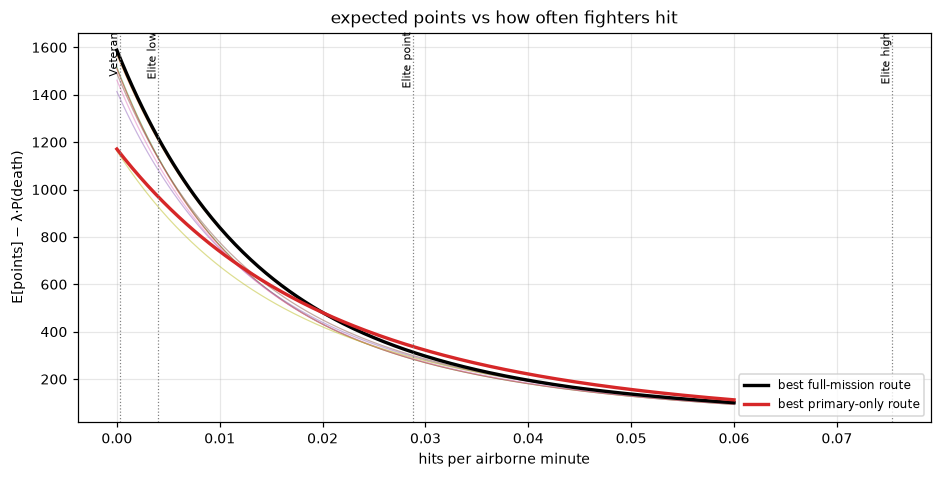

In [65]:
hz = np.linspace(0, 0.06, 241)
full_i = [i for i, c in enumerate(cands) if c["T"]["secondary"] and c["T"]["valid"]]; prim_i = [i for i, c in enumerate(cands) if not c["T"]["secondary"] and c["T"]["valid"]]
V = np.array([[value2(c["ac"], c["T"], replace(A, hit_per_min=h), opp_)["value"] for h in hz] for c in cands])
best_full, best_prim = V[full_i].max(0), V[prim_i].max(0)
cross = hz[np.argmax(best_prim > best_full)] if (best_prim > best_full).any() else None
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, c in enumerate(cands): ax.plot(hz, V[i], lw=.8, alpha=.5, label=None)
ax.plot(hz, best_full, "k", lw=2.2, label="best full-mission route"); ax.plot(hz, best_prim, "C3", lw=2.2, label="best primary-only route")
for k, v in HZ.items(): ax.axvline(v, c="grey", ls=":", lw=.8); ax.annotate({"Veteran (0 hits seen)": "Veteran", "Elite, low (90% bound)": "Elite low", "Elite, point estimate": "Elite point", "Elite, high (90% bound)": "Elite high"}[k], (v, ax.get_ylim()[1]), rotation=90, va="top", ha="right", fontsize=7)
ax.set_xlabel("hits per airborne minute"); ax.set_ylabel("E[points] − λ·P(death)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("expected points vs how often fighters hit")
print("break-even hazard for flying the secondary:", f"{cross:.4f} hits/min" if cross is not None else "none in range",
      "| the Elite point estimate is", f"{elite[0]:.4f}", "| Veteran upper bound (rule of three):", f"{3 / vet[3]:.4f}")

### What the leak does along the route

If the first leak comes at km `k`, what fraction `φ` of the rest of the flight can still be flown? This is the "shorter flight" formula applied to the real plan (one Elite hit: 90 lb/min extra):

a first leak leaves the whole plan flyable (φ = 1) only if it starts after game minute 173 (Veteran leak) / 176 (Elite leak) of 195: the leak is a mission-ender for all but the last ~19 min, because 1694 lb of margin buys only ~19 min of a count-6 leak


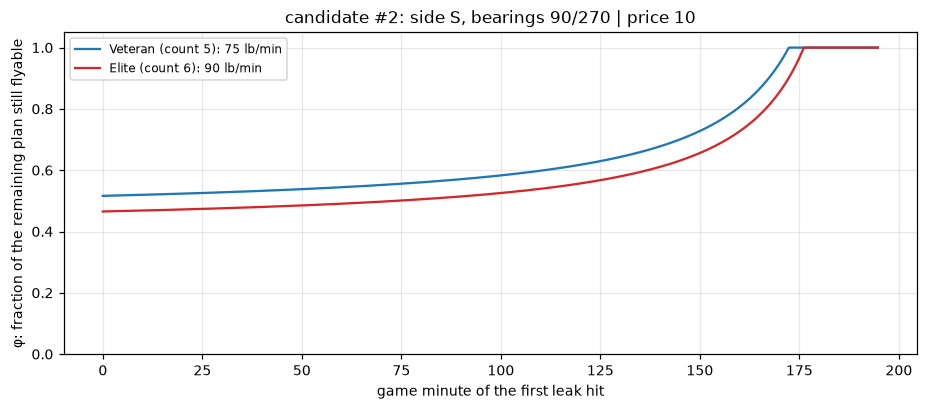

In [66]:
ci = stored_i if stored_i is not None else 0
ac = cands[ci]["ac"]
fig, ax = plt.subplots(figsize=(10, 3.8))
for o, name, col in ((2, "Veteran (count 5)", "C0"), (3, "Elite (count 6)", "C3")):
    ax.plot(ac["t"] / 60, leak_phi(ac, 2 + o + 1), c=col, label=f"{name}: {leak_lb_min(o):.0f} lb/min")
ax.set_xlabel("game minute of the first leak hit"); ax.set_ylabel("φ: fraction of the remaining plan still flyable"); ax.set_ylim(0, 1.05); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title(f"candidate #{ci}: {cands[ci]['tag'][:60]}")
first_ok = lambda o: ac["t"][np.argmax(leak_phi(ac, 2 + o + 1) >= 1)] / 60
print(f"a first leak leaves the whole plan flyable (φ = 1) only if it starts after game minute {first_ok(2):.0f} (Veteran leak) / {first_ok(3):.0f} (Elite leak) of {ac['T_end']/60:.0f}: "
      f"the leak is a mission-ender for all but the last ~{ac['T_end']/60 - first_ok(3):.0f} min, because {ac['F'][-1] - ac['B'][-1]:.0f} lb of margin buys only ~{(ac['F'][-1] - ac['B'][-1]) * 4 / 6 / 60:.0f} min of a count-6 leak")

### The residual: what λ actually prices

With ejection safe by the level-check decision, the only death risk left in this model is ejecting un-level. A **damaged-controls hit (bit `0x04`)** is exactly the case that makes level flight hard (random 0-4 × count of extra control input each frame), and it has the same 33-41 % chance per hit as bay and leak.
So `p_unlevel` is not obviously 0 after a bay hit, which makes it the thing to measure. Here is what it would cost at λ = 30,000:

In [67]:
c0 = cands[stored_i if stored_i is not None else 0]; hz_e = HZ["Elite, point estimate"]
print(f"candidate: {c0['tag']}  | Elite point-estimate hazard {hz_e:.4f}/min")
print(f"{'p_unlevel':>9s} {'P(death)':>9s} {'lambda x P(death)':>18s} {'E[points]':>10s} {'value':>8s}")
for pu in (0, 0.01, 0.05, 0.10, 0.25):
    v = value2(c0["ac"], c0["T"], replace(A, hit_per_min=hz_e, p_unlevel=pu), opp_)
    print(f"{pu:9.0%} {v['p_death']:9.2%} {A.lam * v['p_death']:18.0f} {v['exp_pts']:10.0f} {v['value']:8.0f}")
print("\nIf an un-level ejection after a hit is even 5 % deadly, the death term is worth more than the points at stake: the level-check (and what the ejection sequence does when the plane can't be levelled) is what the risk threshold is really about.")

candidate: side S, bearings 90/270 | price 10  | Elite point-estimate hazard 0.0288/min
p_unlevel  P(death)  lambda x P(death)  E[points]    value
       0%     0.00%                  0        284      284
       1%     0.91%                272        284       12
       5%     4.53%               1360        284    -1075
      10%     9.06%               2719        284    -2435
      25%    22.66%               6798        284    -6514

If an un-level ejection after a hit is even 5 % deadly, the death term is worth more than the points at stake: the level-check (and what the ejection sequence does when the plane can't be levelled) is what the risk threshold is really about.


### The point-optimising plan function, now

```python
def plan_for_points(spec, mission, A, opp):
    for option in candidates(spec, mission):       # order, approach side, attack bearings, radar-price sweep, primary-only
        route = plan(option)                       # hard limits: walls, R ≥ 20 km, SA-14, validate()
        ac    = accrual(route)                     # points accrued / eject multiplier / leak feasibility per 1 km step
        V     = value2(ac, route, A, opp)          # E[points] - lambda * P(death), exact simulators for samples, IDs and fuel
    return argmax(V), the frontier over the hazard
```

Veteran (0 hits seen)     : side N, bearings 90/270 | price 10             E[pts]  1560 of 1588   P(bay hit) 2%   expected hits 0.0   (runner-up by 17)
Elite, low (90% bound)    : side N, bearings 90/270 | price 10             E[pts]  1218 of 1588   P(bay hit) 24%   expected hits 0.7   (runner-up by 11)
Elite, point estimate     : PRIMARY ONLY, side N | price 10                E[pts]   338 of 1171   P(bay hit) 78%   expected hits 3.7   (runner-up by 24)
Elite, high (90% bound)   : PRIMARY ONLY, side N | price 10                E[pts]    71 of 1171   P(bay hit) 98%   expected hits 9.7   (runner-up by 5)


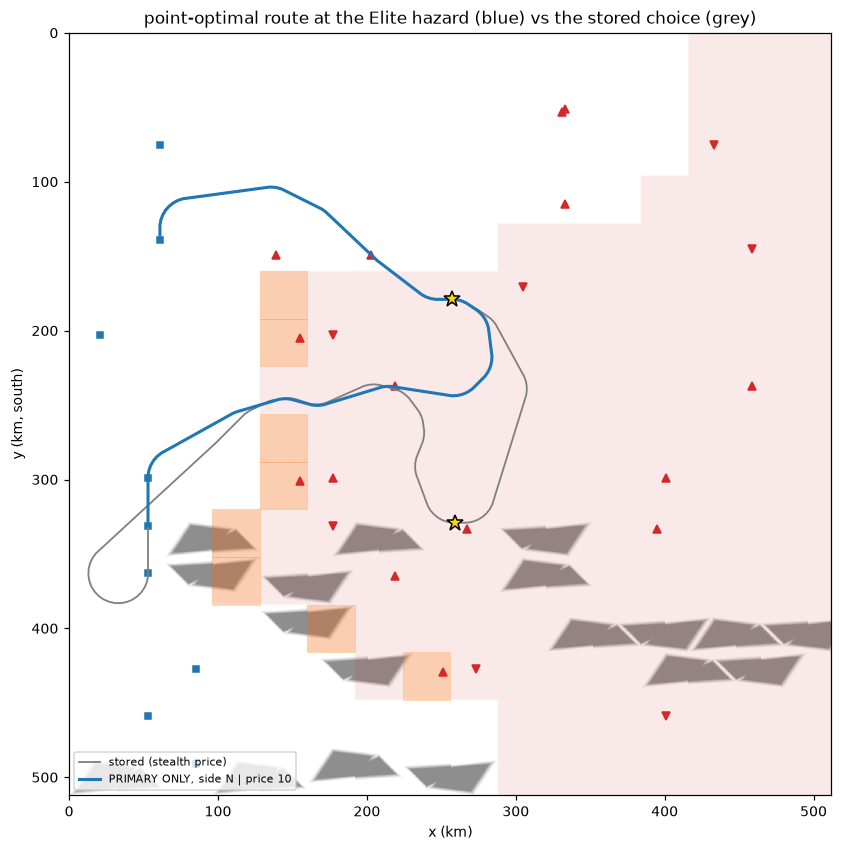

In [68]:
def plan_for_points(cands, A, opp):
    scored = sorted(((value2(c["ac"], c["T"], A, opp), c) for c in cands if c["T"]["valid"]), key=lambda vc: -vc[0]["value"])
    return scored[0][1], scored[0][0], scored

for name, hz_ in HZ.items():
    A_h = replace(A, hit_per_min=hz_)
    best_c, v, ranked = plan_for_points(cands, A_h, opp_)
    print(f"{name:26s}: {best_c['tag']:46s} E[pts] {v['exp_pts']:5.0f} of {v['full']:.0f}   P(bay hit) {v['p_bay']:.0%}   expected hits {v['hits']:.1f}   (runner-up by {v['value'] - ranked[1][0]['value']:.0f})")
best_c, v, _ = plan_for_points(cands, replace(A, hit_per_min=HZ["Elite, point estimate"]), opp_)
fig, ax = show_map(f"point-optimal route at the Elite hazard (blue) vs the stored choice (grey)",
                   routes=[dict(pts=stored["points"], color="grey", lw=1.2, label="stored (stealth price)"), dict(pts=best_c["pts"], color="C0", lw=2, label=best_c["tag"][:40])], labels=False)

### What would change in the real planner, and what still needs learning

| change | why |
|---|---|
| model **fighters**, not just sites | every hit in the logs is a fighter missile; the alert sim's launch probability does not see them |
| score routes by `E[points] − λ·P(death)` with the accrual above | time in the air and the order of events (when the objectives fall relative to the likely hit) matter, which a km cost cannot express |
| treat the hit rate as an input per opponent level and per reaction capability | at Elite it is ~43 % of fighter launches now (no countermeasure used on any of 23); it should fall as reactions are added. At Veteran we have no hit to count |
| P(launch \| launch possible) ≈ 1 | 5 of 6 Elite site episodes in the logs; the alert sim's "launch possible" can be read as a launch |
| replace the hard `landing_reserve_lb` with the flame-out probability | σ = 8.3 % from the flight logs, as above |

**Still open, in order of how much they move the answer:**

1. **Fighter exposure per route.** The rate per airborne minute is crude (clustered, and censored by early endings). What makes a fighter fire is an aircraft alert above 0xC0 plus its nose pointing at us; whether altitude, enemy-cell time or the mission type drives it is not separable with 5 Elite flights.
2. **Un-level ejection** (`p_unlevel`): needs the ejection sequence to be able to level the plane after a controls hit, or a measure of how often it can't.
3. **Ejection multiplier outside enemy cells**: only `2/8` over enemy ground is confirmed; `[2,3,6,4]/8` by the cell's side bits is the decoded table, unverified for the others.
4. **More Elite flights, and Veteran fighter data.** 7 Elite flights (4 with fighter launches, 3 with hits) carry the whole hazard estimate, and nothing in the Veteran logs measures fighters at all (none launched). Every flight with the new reaction code adds to it and shows whether the 43 % falls.

## Where to go next

| to understand | read |
|---|---|
| the design and the numbers behind each rule | `docs/design/planner.md`, `docs/game/radar.md`, `docs/game/fuel.md` |
| how the autopilot consumes `route.json` | `docs/design/autopilot.md`, `src/f19/pilot/` |
| self-checks of the planner model | `python analysis/planner/checks.py`, `tests/test_planner_checks.py` |
| the slow golden runs | `uv run pytest --run-slow` (`tests/test_planner_golden.py`) |

Source map: `world.py` (Step 2) · `radar.py` (3) · `fuelplan.py` (4, 8) · `router.py` (5, 7) · `planner.py` (6, 10) · `alertsim.py` (9) · `loiter.py` (10) · `report.py` (11) · `api.py` (12).